## TMA4215- Prosjekt part 1

### Bruk av AI-verktøy

Jeg har brukt GPT og Codex som støtteverktøy gjennom prosjektet. Det har først og fremst hjulpet meg med å tolke oppgaveteksten og få enkelte deler forklart på en enklere måte. Jeg har også brukt AI til å skrive om dikusjonsdeler for å få mer flyt i teksten, pyhton-syntaks, debugging og til å vurdere om numeriske resultater virker rimelige. I Codex har jeg for eksempel brukt agenten når jeg ikke har forstått hvor en feil i koden oppstår. Siden agenten kan se flere kodeceller i sammenheng, har den kunnet hjelpe meg med å finne hvor feilen ligger og foreslå hvordan den kan rettes. 

Et eksempel hvor GPT var mangelfull har vært noen ganger hvor har bedt om en oppsummering av nøyaktig hva en deloppgave spør om for å sjekke av at alt er gjort, og GPT har oversett et mindre krav eller steg i oppgaveteksten. Dette fanger jeg opp fordi jeg leser den ordinære oppgaveteksten parallelet med den enklere versjonen fra GPT. 

Alt av kode GPT har rettet for meg har jeg gått nøye igjennom og forstått.



In [316]:
import numpy as np
import matplotlib.pyplot as plt
import math
import time


## 1a)

##### Lagrange funksjon

In [317]:
def lagrange_interpolation(x_nodes, y_nodes, x):
    #Antall interpolasjonsnoder
    num_nodes = len(x_nodes)

    #Initialiser interpolasjonspolynomet med null
    p = np.zeros_like(x, dtype=float)

    #Bygg opp Lagrange-polynomet
    for i in range(num_nodes):

        #L_i(x) = 1
        L_i = np.ones_like(x, dtype=float)

        #Bygg Lagrange-basisfunksjonen L_i(x)
        for j in range(num_nodes):
            if i != j:
                L_i *= (x - x_nodes[j]) / (x_nodes[i] - x_nodes[j])

        #Legger til bidraget y_i * L_i(x)
        p += y_nodes[i] * L_i

    return p

##### Ekvidistante noder

In [318]:
def equidistant_nodes(a, b, n):
    #Et polynom av grad n bruker n + 1 interpolasjonsnoder
    return np.linspace(a, b, n + 1)

##### Chebychev noder

In [319]:
def chebyshev_nodes(a, b, n):
    #Indekser for de n + 1 nodene
    i = np.arange(n + 1)

    #Chebyshev-noder på intervallet [-1, 1]
    x_cheb = np.cos((2 * i + 1) * np.pi / (2 * (n + 1)))

    #Generaliserte noder [a, b]
    x_cheb = (b - a) / 2 * x_cheb + (a + b) / 2

    return x_cheb

##### Runge-funksjonen

In [320]:
def runge(x):
    return 1 / (1 + x**2)

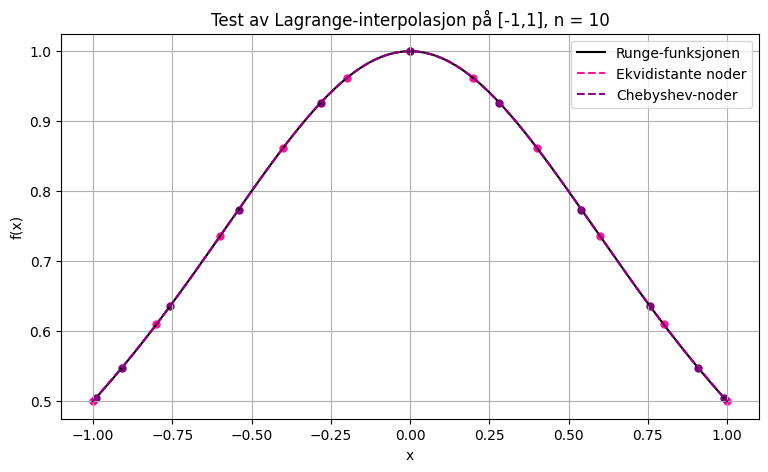

In [321]:
#Test på standardintervallet [-1, 1]
a_test = -1
b_test = 1
n_test = 10


x_test = np.linspace(a_test, b_test, 1000)
y_exact_test = runge(x_test)

#Ekvidistante noder
x_eq_test = equidistant_nodes(a_test, b_test, n_test)
y_eq_test = runge(x_eq_test)
p_eq_test = lagrange_interpolation(x_eq_test, y_eq_test, x_test)

#Chebyshev-noder på [-1, 1]
i = np.arange(n_test + 1)
x_cheb_test = np.cos((2 * i + 1) * np.pi / (2 * (n_test + 1)))
y_cheb_test = runge(x_cheb_test)
p_cheb_test = lagrange_interpolation(x_cheb_test, y_cheb_test, x_test)


plt.figure(figsize=(9, 5))

plt.plot(x_test, y_exact_test, color="black", linewidth=1.5, label="Runge-funksjonen")

plt.plot(x_test, p_eq_test, "--", color="deeppink", label="Ekvidistante noder")

plt.plot(x_test, p_cheb_test, "--", color="purple", label="Chebyshev-noder")

plt.scatter(x_eq_test, y_eq_test, color="deeppink", s=25)

plt.scatter(x_cheb_test, y_cheb_test, color="purple", s=25)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Test av Lagrange-interpolasjon på [-1,1], n = 10")
plt.legend()
plt.grid()
plt.show()



##### Parametere og tett grid

In [322]:
a = -5
b = 5
n = 10
x = np.linspace(a, b, 1000)

#Eksakte verdier av Runge-funksjonen
y_exact = runge(x)

##### Beregn begge interpolasjonene

In [323]:
#Ekvidistante 
x_eq = equidistant_nodes(a, b, n)
y_eq = runge(x_eq)
p_eq = lagrange_interpolation(x_eq, y_eq, x)


#Chebyshev
x_cheb = chebyshev_nodes(a, b, n)
y_cheb = runge(x_cheb)
p_cheb = lagrange_interpolation(x_cheb, y_cheb, x)

#### Plot

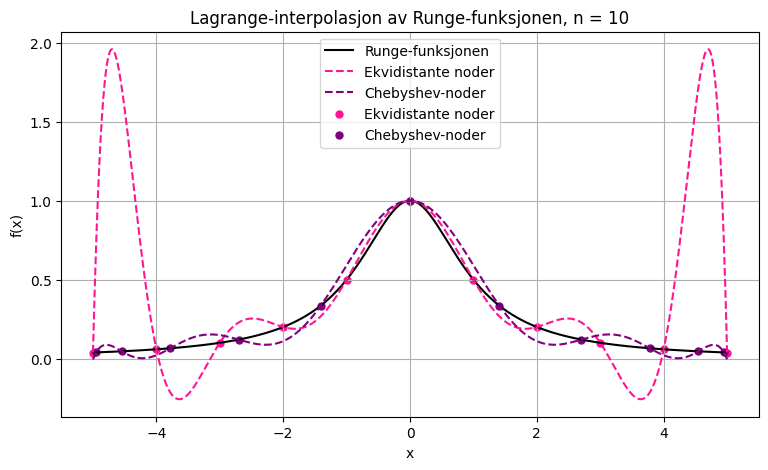

In [324]:
plt.figure(figsize=(9, 5))

#Eksakt Runge-funksjon
plt.plot(x, y_exact, label="Runge-funksjonen", color="black")

#Interpolasjonspolynomer
plt.plot(x, p_eq, "--", label="Ekvidistante noder", color="deeppink")
plt.plot(x, p_cheb, "--", label="Chebyshev-noder", color="purple")

#Interpolasjonsnoder
plt.scatter(x_eq, y_eq, s=25, label="Ekvidistante noder", color="deeppink")
plt.scatter(x_cheb, y_cheb, s=25, label="Chebyshev-noder", color="purple")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Lagrange-interpolasjon av Runge-funksjonen, n = 10")
plt.legend()
plt.grid()


plt.show()


I denne oppgaven er $n$ graden på interpolasjonspolynomet, slik at man bruker $n+1$ interpolasjonsnoder.

For ekvidistante noder på $[a,b]$ bruker man

$$
x_i = a + i\frac{b-a}{n},
\qquad i=0,\dots,n.
$$

Her er nodene jevnt fordelt over hele intervallet. Når $n$ øker, får man flere noder, men for Runge-funksjonen på $[-5,5]$ forventes det likevel at interpolasjonen blir dårligere nær endepunktene. Polynomet kan begynne å oscillere kraftig der selv om det treffer funksjonen eksakt i alle nodene.
<br><br>

For Chebyshev-noder bruker man først

$$
t_i =
\cos\left(
\frac{(2i+1)\pi}{2(n+1)}
\right),
\qquad i=0,\dots,n,
$$

på intervallet $[-1,1]$.

Disse transformeres til et generelt intervall $[a,b]$ med

$$
x_i =
\frac{b-a}{2}t_i + \frac{a+b}{2}.
$$

Chebyshev-nodene ligger tettere nær endepunktene enn i midten av intervallet. Derfor kan man forvente at det reduserer de store oscilleringene nær endepunktene.

<br><br>



**Prediksjonen følger derfor:**
<br><br>
For ekvidistante noder forventer jeg at feilen nær endepunktene blir større når $n$ økes fra $10$ til $15$, $20$ og $30$, selv om antall noder øker. For Chebyshev-noder forventer jeg at feilen blir mindre når $n$ øker, og at interpolasjonen følger Runge-funksjonen bedre over hele intervallet. 
<br><br>

#### Test for ulik n

n = 10: maksimal feil = 1.915633
n = 15: maksimal feil = 2.106860
n = 20: maksimal feil = 59.768399
n = 30: maksimal feil = 2384.728568


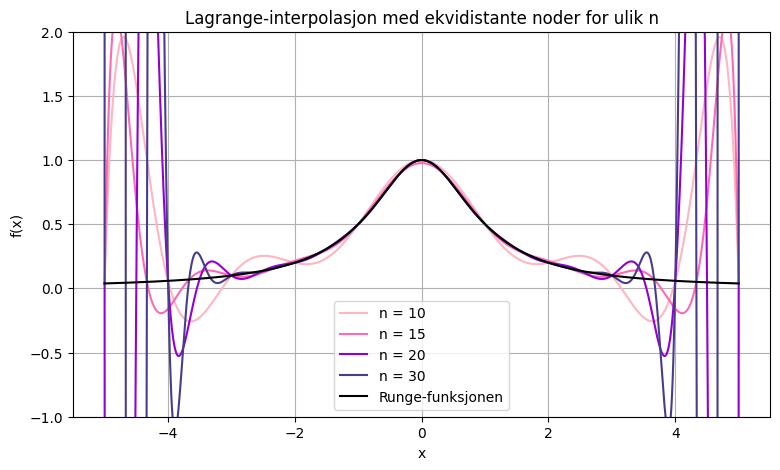

In [325]:
#testverdier av n
n_values = [10, 15, 20, 30]
colors=["lightpink", "hotpink", "darkviolet", "darkslateblue"]

plt.figure(figsize=(9, 5))

for i, n in enumerate(n_values):
    x_eq = equidistant_nodes(a, b, n)
    y_eq = runge(x_eq)
    p_eq = lagrange_interpolation(x_eq, y_eq, x)

    plt.plot(x, p_eq, label=f"n = {n}", color=colors[i])

    #Beregner maksimal absolutt feil
    max_error = np.max(np.abs(y_exact - p_eq))
    print(f"n = {n}: maksimal feil = {max_error:.6f}")

#Eksakt Runge-funksjon
plt.plot(x, y_exact, label="Runge-funksjonen", color="black", linewidth=1.5)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Lagrange-interpolasjon med ekvidistante noder for ulik n")

#Zoomer inn rundt Runge-funksjonen
plt.ylim(-1, 2)

plt.legend()
plt.grid()
plt.show()

n = 10: maksimal interpolasjonsfeil = 0.109154
n = 15: maksimal interpolasjonsfeil = 0.083094
n = 20: maksimal interpolasjonsfeil = 0.015333
n = 30: maksimal interpolasjonsfeil = 0.002061


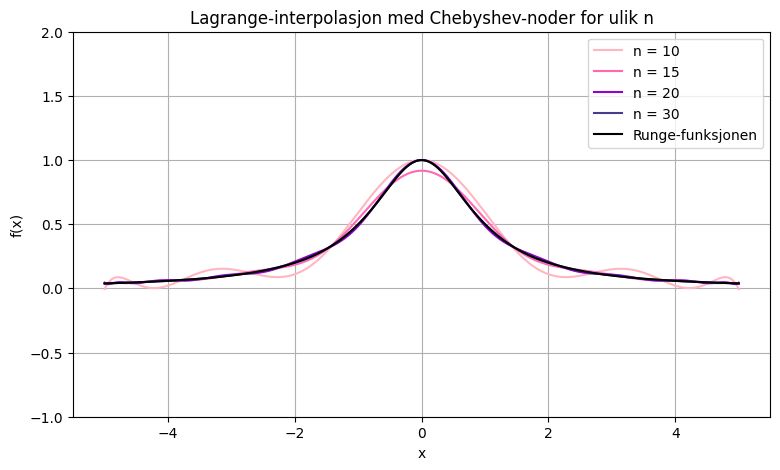

In [326]:
#Verdier av n vi vil teste
n_values = [10, 15, 20, 30]
colors=["lightpink", "hotpink", "darkviolet", "darkslateblue"]

plt.figure(figsize=(9, 5))

for i, n in enumerate(n_values):
    x_cheb = chebyshev_nodes(a, b, n)
    y_cheb = runge(x_cheb)
    p_cheb = lagrange_interpolation(x_cheb, y_cheb, x)

    #Plotter interpolasjonspolynomet
    plt.plot(x, p_cheb, label=f"n = {n}", color=colors[i])

    #Skriver ut maksimal feil
    max_error = np.max(np.abs(y_exact - p_cheb))
    print(f"n = {n}: maksimal interpolasjonsfeil = {max_error:.6f}")

# Plotter Runge-funksjonen til slutt
plt.plot(x, y_exact, color="black", linewidth=1.5, label="Runge-funksjonen", zorder=10)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Lagrange-interpolasjon med Chebyshev-noder for ulik n")
plt.ylim(-1, 2)
plt.legend()
plt.grid()
plt.show()

### Kommentar
det ser ut som forventet. Det var overraskende akkurat hvor stort avvik det var for ekvidistante. Man kan samtidig se at for ekvidistante så er det mindre n som tidligere faller ut av bane, men den gir også minst maksimal feil. 

Det spesielle med Chebyshev-noder er ikke bare at de ligger tettere ved endepunktene, men at de er valgt slik at interpolasjonsfeilen blir så lite som mulig.

Interpolasjonsfeilen kan skrives som

$$
f(x)-p_n(x)
=
\frac{f^{(n+1)}(\xi_x)}{(n+1)!}
\prod_{i=0}^{n}(x-x_i).
$$

Feilen styres derfor blant annet av nodalpolynomet

$$
\pi_{n+1}(x)
=
\prod_{i=0}^{n}(x-x_i).
$$

For Chebyshev-noder på $[-1,1]$,

$$
x_i
=
\cos\left(
\frac{(2i+1)\pi}{2(n+1)}
\right),
$$

er dette produktet proporsjonalt med Chebyshev-polynomet $T_{n+1}(x)$.

Chebyshev-polynomene har egenskapen

$$
|T_{n+1}(x)| \leq 1,
\qquad x\in[-1,1].
$$

Dermed blir den maksimale størrelsen til nodalpolynomet godt kontrollert, noe som igjen gir en mindre interpolasjonsfeil.

For et generelt intervall $[a,b]$ gir dette feilgrensen

$$
\|f-p_n\|_\infty
\leq
\frac{(b-a)^{n+1}}
{2^{2n+1}(n+1)!}
M_{n+1},
$$

der

$$
M_{n+1}
=
\max_{\zeta\in[a,b]}
|f^{(n+1)}(\zeta)|.
$$

Derfor plasserer Chebyshev-nodene flere punkter nær endepunktene, fordi det er der globale interpolasjonspolynomer lett kan begynne å oscillere kraftig. Dette reduserer feilen på endene sammenlignet med ekvidistante noder.

Hovedideen er at Chebyshev-nodene gjør leddet

$$
\max_x
\left|
\prod_{i=0}^{n}(x-x_i)
\right|
$$

mindre. Dermed reduseres interpolasjonsfeilen, spesielt nær endepunktene der ekvidistante noder ofte gir store oscillasjoner.

n = 10: maksimal interpolasjonsfeil = 7.912642e-04
n = 15: maksimal interpolasjonsfeil = 6.731283e-05
n = 20: maksimal interpolasjonsfeil = 5.846810e-06
n = 30: maksimal interpolasjonsfeil = 5.555246e-08


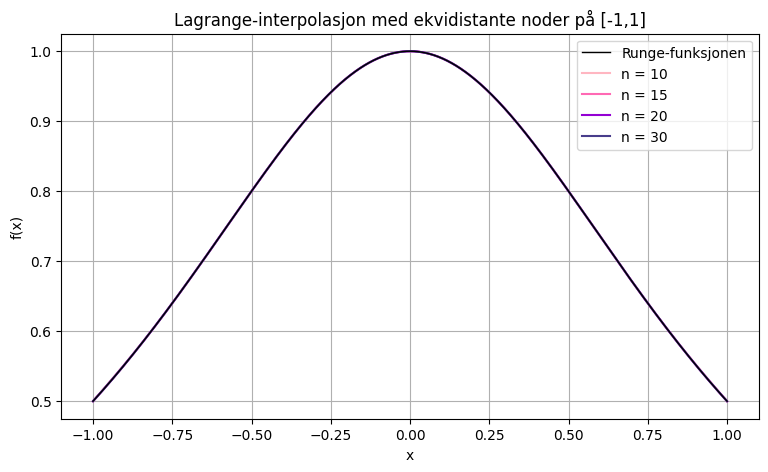

In [327]:
a = -1
b = 1
x = np.linspace(a, b, 1000)

y_exact = runge(x)

#testverdier
n_values = [10, 15, 20, 30]
colors=["lightpink", "hotpink", "darkviolet", "darkslateblue"]

plt.figure(figsize=(9, 5))


plt.plot(x, y_exact, color="black", linewidth=1, label="Runge-funksjonen", zorder=10) #tegner eksakt oppå andre 

for i, n in enumerate(n_values):
    x_eq = equidistant_nodes(a, b, n)
    y_eq = runge(x_eq)
    p_eq = lagrange_interpolation(x_eq, y_eq, x)

    plt.plot(x, p_eq, label=f"n = {n}", color=colors[i])

    #maksimal interpolasjonsfeil
    max_error = np.max(np.abs(y_exact - p_eq))
    print(f"n = {n}: maksimal interpolasjonsfeil = {max_error:.6e}")



plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Lagrange-interpolasjon med ekvidistante noder på [-1,1]")
plt.legend()
plt.grid()
plt.show()

n = 10: maksimal interpolasjonsfeil = 6.158394e-05
n = 15: maksimal interpolasjonsfeil = 1.501630e-06
n = 20: maksimal interpolasjonsfeil = 9.156102e-09
n = 30: maksimal interpolasjonsfeil = 1.362077e-12


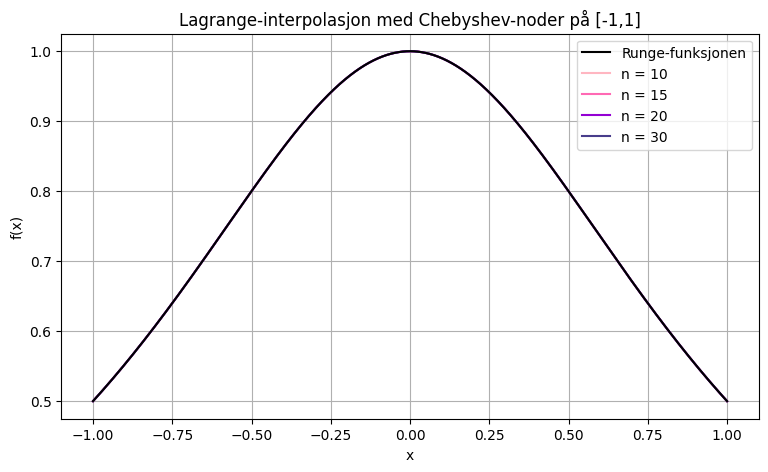

In [328]:
plt.figure(figsize=(9, 5))
colors=["lightpink", "hotpink", "darkviolet", "darkslateblue"]

# Plotter Runge-funksjonen 
plt.plot(x, y_exact, color="black", linewidth=1.5, label="Runge-funksjonen", zorder=10)

for i, n in enumerate(n_values):
    x_cheb = chebyshev_nodes(a, b, n)
    y_cheb = runge(x_cheb)
    p_cheb = lagrange_interpolation(x_cheb, y_cheb, x)

    # Plotter interpolasjonspolynomet
    plt.plot(x, p_cheb, label=f"n = {n}", color=colors[i])

    # Beregner maksimal interpolasjonsfeil
    max_error = np.max(np.abs(y_exact - p_cheb))
    print(f"n = {n}: maksimal interpolasjonsfeil = {max_error:.6e}")


plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Lagrange-interpolasjon med Chebyshev-noder på [-1,1]")
plt.legend()
plt.grid()
plt.show()

### Observasjon

På intervallet $[-1,1]$ gir begge nodetypene en god interpolasjon med liten feil. For begge metodene avtar den maksimale interpolasjonsfeilen tydelig når $n$ øker.

Chebyshev-nodene gir likevel lavere feil enn de ekvidistante nodene. For $n=30$ er den maksimale feilen omtrent $5.6\cdot10^{-8}$ for ekvidistante noder, mens den er omtrent $1.4\cdot10^{-12}$ for Chebyshev-noder.

Dette skiller seg fra intervallet $[-5,5]$, der interpolasjon med ekvidistante noder fikk store oscillasjoner nær endepunktene når $n$ økte, mens for dette intervallet avtar feilen når $n$ øker. For Chebyshev-nodene er trenden den samme, når $n$ økte ga den en stabil og forbedret approksimasjon.

## 1b)


Man skal vise at interpolasjon med både ekvidistante noder og Chebyshev-noder konvergerer i maks-normen og 2-normen for funksjonene

- $f_1(x)=\cos(2\pi x)$ på $[0,1]$,
- $f_2(x)=e^{3x}\sin(2x)$ på $[0,\pi/4]$.

På et endelig intervall gjelder
$$
\|f-p_n\|_2 \leq \sqrt{b-a}\,\|f-p_n\|_\infty.
$$
Siden feilen for maksnormen er større enn feilen for 2-normen, er det tilstrekkelig å vise konvergens mot 0 for maksnormen. 

#### Interpolasjonsfeilen

Feilformelen for Lagrange-interpolasjon gir
$$
\|f-p_n\|_\infty
\leq
\frac{M_{n+1}}{(n+1)!}
\max_{x\in[a,b]}
\left|\prod_{i=0}^{n}(x-x_i)\right|,
$$
der
$$
M_{n+1}=\max_{x\in[a,b]}|f^{(n+1)}(x)|.
$$

Siden både $x$ og nodene ligger i $[a,b]$, er $|x-x_i|\leq b-a$. Dermed
$$
\max_{x\in[a,b]}
\left|\prod_{i=0}^{n}(x-x_i)\right|
\leq (b-a)^{n+1}.
$$
Denne grensen gjelder begge nodetypene, og man bruker den for de ekvidistante nodene.

For Chebyshev-nodene kan man bruke en skarpere grense. Med $n+1$ noder på $[-1,1]$ gjelder
$$
\max_{\tilde{x}\in[-1,1]}
|\omega_{\mathrm{Cheb}}(\tilde{x})|=2^{-n},
$$
der $\omega$ er nodalpolynomet. Transformasjonen
$$
x=\frac{b-a}{2}\tilde{x}+\frac{b+a}{2}
$$
skalerer hver av de $n+1$ faktorene i nodalpolynomet med $(b-a)/2$. På $[a,b]$ får man derfor
$$
\max_{x\in[a,b]}|\omega_{\mathrm{Cheb}}(x)|
=
2^{-n}\left(\frac{b-a}{2}\right)^{n+1}.
$$

#### Funksjonen $f_1(x)=\cos(2\pi x)$

Den $k$-te deriverte er sinus eller cosinus multiplisert med $(2\pi)^k$, opp til fortegn. På $[0,1]$ gir dette
$$
\|f_1^{(k)}\|_\infty=(2\pi)^k.
$$

Siden intervallet har lengde 1, får man for ekvidistante noder
$$
\|f_1-p_n\|_\infty
\leq
\frac{(2\pi)^{n+1}}{(n+1)!}.
$$

For Chebyshev-noder får man
$$
\|f_1-p_n\|_\infty
\leq
\frac{(2\pi)^{n+1}2^{-2n-1}}{(n+1)!}.
$$

Begge grensene går mot null når $n\to\infty$, fordi fakultetet vokser raskere enn en fast konstant opphøyd i $n+1$. Dermed konvergerer interpolasjonen i maks-normen for begge nodetypene.

#### Funksjonen $f_2(x)=e^{3x}\sin(2x)$

For å finne en grense for de deriverte skriver man
$$
f_2(x)=\operatorname{Im}\left(e^{(3+2i)x}\right).
$$
Derivasjon gir
$$
f_2^{(k)}(x)
=
\operatorname{Im}\left((3+2i)^k e^{(3+2i)x}\right).
$$

Absoluttverdien av imaginærdelen er høyest absoluttverdien av det komplekse tallet. Siden $|3+2i|=\sqrt{13}$, får man
$$
|f_2^{(k)}(x)|
\leq
(\sqrt{13})^k e^{3x}
\leq
(\sqrt{13})^k e^{3\pi/4}
$$
for $x\in[0,\pi/4]$. Dermed
$$
M_{n+1}\leq(\sqrt{13})^{n+1}e^{3\pi/4}.
$$

Intervallet har lengde $\pi/4$. For ekvidistante noder gir dette
$$
\|f_2-p_n\|_\infty
\leq
e^{3\pi/4}
\frac{(\sqrt{13}\,\pi/4)^{n+1}}{(n+1)!}.
$$

For Chebyshev-noder får man
$$
\|f_2-p_n\|_\infty
\leq
e^{3\pi/4}
\frac{2^{-n}(\sqrt{13}\,\pi/8)^{n+1}}{(n+1)!}.
$$

Også disse grensene går mot null når $n\to\infty$. Generelt gjelder derfor
$$
\frac{C^{n+1}}{(n+1)!}\longrightarrow 0
$$
for enhver fast konstant $C>0$. Dette følger for eksempel av at forholdet mellom to påfølgende ledd er $C/(n+2)$, som går mot null.

#### Konklusjon

Feilgrensene er uavhengige av $x$ og går mot null for begge funksjonene og begge nodetypene. Derfor
$$
\|f-p_n\|_\infty\longrightarrow 0.
$$
Fra
$$
\|f-p_n\|_2\leq\sqrt{b-a}\,\|f-p_n\|_\infty
$$
følger også konvergens i 2-normen.

Interpolasjonen konvergerer altså i begge normene for både ekvidistante noder og Chebyshev-noder. 

##### Funksjonene


In [329]:
def f1(x):
    return np.cos(2 * np.pi * x)


def f2(x):
    return np.exp(3 * x) * np.sin(2 * x)

##### Funksjon for normene

In [330]:
def interpolation_errors(f_exact, p, a, b, N):
    #Feil på det tette gridet
    error = f_exact - p

    #Approksimasjon av maks-normen
    max_error = np.max(np.abs(error))

    #Approksimasjon av 2-normen
    l2_error = np.sqrt((b - a) / N) * np.sqrt(np.sum(error**2))

    return max_error, l2_error

#### Felles funksjon for feilberegning


In [331]:
def compute_errors(f, a, b, n_values, node_function):
    #Samme tette grid for alle grader, (gitt i oppgaven)
    N = 100 * max(n_values)
    x = np.linspace(a, b, N + 1)
    f_exact = f(x)

    max_errors = []
    l2_errors = []

    for n in n_values:
        x_nodes = node_function(a, b, n)
        y_nodes = f(x_nodes)
        p = lagrange_interpolation(x_nodes, y_nodes, x)

        max_error, l2_error = interpolation_errors(f_exact, p, a, b, N)
        max_errors.append(max_error)
        l2_errors.append(l2_error)

    return max_errors, l2_errors


##### Parametere og feil for f1 og f2


In [332]:
n_values = np.arange(1, 35)
a1, b1 = 0, 1
a2, b2 = 0, np.pi / 4

max_errors_eq_f1, l2_errors_eq_f1 = compute_errors(f1, a1, b1, n_values, equidistant_nodes)

max_errors_cheb_f1, l2_errors_cheb_f1 = compute_errors(f1, a1, b1, n_values, chebyshev_nodes)

max_errors_eq_f2, l2_errors_eq_f2 = compute_errors(f2, a2, b2, n_values, equidistant_nodes)

max_errors_cheb_f2, l2_errors_cheb_f2 = compute_errors(f2, a2, b2, n_values, chebyshev_nodes)



##### Plot feilene for f2


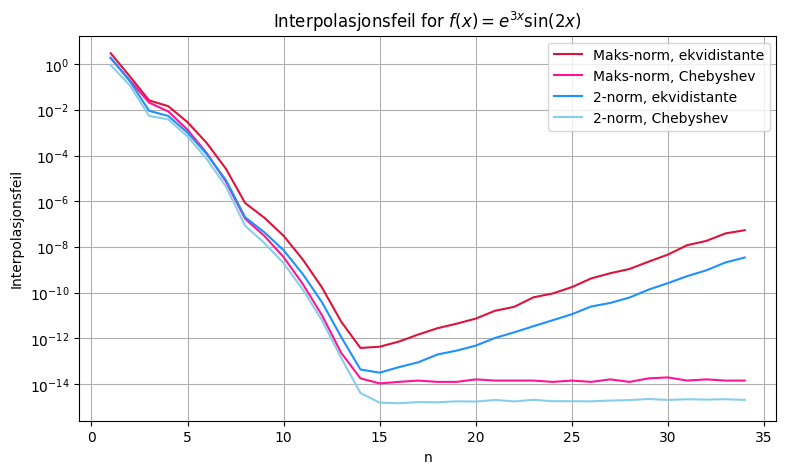

In [333]:
plt.figure(figsize=(9, 5))

#Maks-norm
plt.semilogy(n_values, max_errors_eq_f2, label="Maks-norm, ekvidistante", color="crimson")
plt.semilogy(n_values, max_errors_cheb_f2,  label="Maks-norm, Chebyshev", color="deeppink")

#2-norm
plt.semilogy(n_values, l2_errors_eq_f2,  label="2-norm, ekvidistante", color="dodgerblue")
plt.semilogy(n_values, l2_errors_cheb_f2,  label="2-norm, Chebyshev", color="skyblue")

plt.xlabel("n")
plt.ylabel("Interpolasjonsfeil")
plt.title(r"Interpolasjonsfeil for $f(x)=e^{3x}\sin(2x)$")
plt.legend()
plt.grid()
plt.show()


### Teoretisk feilgrense for $f(x)=\cos(2\pi x)$

Fra Theorem 6.2 er interpolasjonsfeilen

$$
f(x)-p_n(x)
=
\frac{f^{(n+1)}(\xi)}{(n+1)!}
\prod_{i=0}^{n}(x-x_i),
$$

og dermed

$$
\|f-p_n\|_\infty
\leq
\frac{M_{n+1}}{(n+1)!}
\max_{x\in[0,1]}
\left|
\prod_{i=0}^{n}(x-x_i)
\right|,
$$

der

$$
M_{n+1}
=
\max_{x\in[0,1]}
|f^{(n+1)}(x)|.
$$

For

$$
f(x)=\cos(2\pi x)
$$

består den $k$-te deriverte av sinus eller cosinus multiplisert med $(2\pi)^k$. Derfor

$$
\|f^{(k)}\|_\infty=(2\pi)^k.
$$

Spesielt får man

$$
M_{n+1}=(2\pi)^{n+1}.
$$

Feilgrensen blir derfor

$$
\|f-p_n\|_\infty
\leq
\frac{(2\pi)^{n+1}}{(n+1)!}
\max_{x\in[0,1]}
\left|
\prod_{i=0}^{n}(x-x_i)
\right|.
$$

Forskjellen mellom ekvidistante og Chebyshev-noder ligger altså i nodalpolynomet

$$
\prod_{i=0}^{n}(x-x_i).
$$

### Feilgrenser for de to nodetypene

For ekvidistante noder på $[0,1]$ har vi $|x-x_i|\leq 1$. Dermed

$$
\max_{x\in[0,1]}\left|\prod_{i=0}^{n}(x-x_i)\right|\leq 1.
$$

Dette gir feilgrensen

$$
\boxed{
\|f-p_n^{eq}\|_\infty
\leq \frac{(2\pi)^{n+1}}{(n+1)!}
}
$$

For Chebyshev-noder på $[0,1]$ er maksimum av nodalpolynomet kjent:

$$
\max_{x\in[0,1]}
\left|\prod_{i=0}^{n}(x-x_i)\right|
=\frac{1}{2^{2n+1}}.
$$

Dermed får man

$$
\boxed{
\|f-p_n^{cheb}\|_\infty
\leq \frac{(2\pi)^{n+1}}{2^{2n+1}(n+1)!}
}
$$

Begge grensene går mot null når $n\to\infty$, siden fakultetet vokser raskere enn eksponentialleddet. Dette viser teoretisk konvergens for begge nodetypene.

#### Funksjon for nodalpolynomet

In [334]:
def nodal_polynomial_max(x_nodes, x_grid):
    #Starter med produktet lik 1
    nodal_poly = np.ones_like(x_grid)

    for x_i in x_nodes:
        nodal_poly *= (x_grid - x_i)

    #Returnerer maksimal absoluttverdi på gridet
    return np.max(np.abs(nodal_poly))

##### Beregner feilgrense

In [335]:
#Grid for numerisk estimering av nodalpolynomets maksimum
N1 = 100 * max(n_values)
x1 = np.linspace(a1, b1, N1 + 1)

#Garanterte feilgrenser
bounds_eq_f1 = []
bounds_cheb_f1 = []

omega_eq_values = []
omega_cheb_values = []

#Skarpere, men numerisk estimerte feilgrenser
bounds_eq_est = []
bounds_cheb_est = []

for n in n_values:

    #Maksimum av den (n+1)-te deriverte
    M = (2 * np.pi)**(n + 1)

    #Ekvidistante 
    x_eq = equidistant_nodes(a1, b1, n)
    omega_eq = nodal_polynomial_max(x_eq, x1)

    #Generell grense
    bound_eq = M / math.factorial(n + 1)

    bounds_eq_f1.append(bound_eq)
    omega_eq_values.append(omega_eq)

    #Skarpere estimat basert på nodalpolynomet
    bounds_eq_est.append( M / math.factorial(n + 1) * omega_eq)

    #Chebyshev
    x_cheb = chebyshev_nodes(a1, b1, n)
    omega_cheb = nodal_polynomial_max(x_cheb, x1)

    #Eksakt maksimum av nodalpolynomet på [0,1]
    omega_cheb_exact = 1 / 2**(2*n + 1)

    #Garantert feilgrense
    bound_cheb = M / math.factorial(n + 1) * omega_cheb_exact

    bounds_cheb_f1.append(bound_cheb)
    omega_cheb_values.append(omega_cheb)

    #Numerisk estimert feilgrense
    bounds_cheb_est.append(
        M / math.factorial(n + 1) * omega_cheb
    )

/var/folders/c7/lwmw8lr56cv692xxwvnx45pm0000gn/T/ipykernel_72338/525083620.py:39: RuntimeWarning: divide by zero encountered in scalar divide
  omega_cheb_exact = 1 / 2**(2*n + 1)


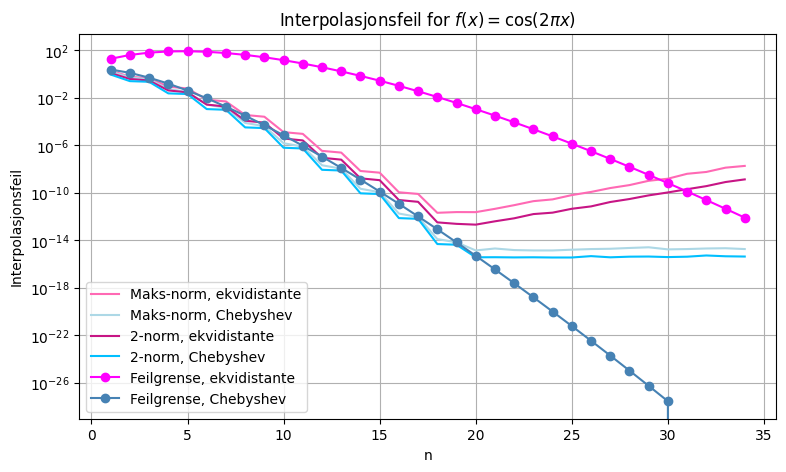

In [336]:
plt.figure(figsize=(9, 5))

#Numerisk maks-norm
plt.semilogy(n_values, max_errors_eq_f1, label="Maks-norm, ekvidistante", color="hotpink")

plt.semilogy(n_values, max_errors_cheb_f1, label="Maks-norm, Chebyshev", color="lightblue")

#Numerisk 2-norm
plt.semilogy(n_values, l2_errors_eq_f1, label="2-norm, ekvidistante", color="mediumvioletred")

plt.semilogy(n_values, l2_errors_cheb_f1, label="2-norm, Chebyshev", color="deepskyblue")

#Teoretiske feilgrenser
plt.semilogy(n_values, bounds_eq_f1,  '-o', label="Feilgrense, ekvidistante", color="fuchsia")

plt.semilogy(n_values, bounds_cheb_f1, '-o', label="Feilgrense, Chebyshev", color="steelblue")

plt.xlabel("n")
plt.ylabel("Interpolasjonsfeil")
plt.title(r"Interpolasjonsfeil for $f(x)=\cos(2\pi x)$")
plt.legend()
plt.grid()
plt.show()

#### printer noen konkrete verdier

In [337]:
#Sammenlign feilgrensene med numeriske resultater
for i, n in enumerate(n_values):

    #Numeriske maks-feil
    error_eq = max_errors_eq_f1[i]
    error_cheb = max_errors_cheb_f1[i]

    #Forhold mellom estimert feilgrense og observert feil
    ratio_eq = bounds_eq_est[i] / error_eq
    ratio_cheb = bounds_cheb_est[i] / error_cheb

    print(f"\nn = {n}")

    print("Ekvidistante noder:")
    print(f"  Numerisk feil:          {error_eq:.3e}")
    print(f"  Garantert feilgrense:   {bounds_eq_f1[i]:.3e}")
    print(f"  Estimert feilgrense:    {bounds_eq_est[i]:.3e}")
    print(f"  Forholdstall:           {ratio_eq:.2f}")
    print(f"  Maks nodalpolynom:      {omega_eq_values[i]:.3e}")

    print("Chebyshev-noder:")
    print(f"  Numerisk feil:          {error_cheb:.3e}")
    print(f"  Garantert feilgrense:   {bounds_cheb_f1[i]:.3e}")
    print(f"  Estimert feilgrense:    {bounds_cheb_est[i]:.3e}")
    print(f"  Forholdstall:           {ratio_cheb:.2f}")
    print(f"  Maks nodalpolynom:      {omega_cheb_values[i]:.3e}")

    #Sammenlign størrelsen på nodalpolynomene
    omega_ratio = omega_eq_values[i] / omega_cheb_values[i]

    print(f"Nodalpolynom: ekvidistant/Chebyshev = {omega_ratio:.2f}")


n = 1
Ekvidistante noder:
  Numerisk feil:          2.000e+00
  Garantert feilgrense:   1.974e+01
  Estimert feilgrense:    4.935e+00
  Forholdstall:           2.47
  Maks nodalpolynom:      2.500e-01
Chebyshev-noder:
  Numerisk feil:          1.606e+00
  Garantert feilgrense:   2.467e+00
  Estimert feilgrense:    2.467e+00
  Forholdstall:           1.54
  Maks nodalpolynom:      1.250e-01
Nodalpolynom: ekvidistant/Chebyshev = 2.00

n = 2
Ekvidistante noder:
  Numerisk feil:          6.113e-01
  Garantert feilgrense:   4.134e+01
  Estimert feilgrense:    1.989e+00
  Forholdstall:           3.25
  Maks nodalpolynom:      4.811e-02
Chebyshev-noder:
  Numerisk feil:          5.503e-01
  Garantert feilgrense:   1.292e+00
  Estimert feilgrense:    1.292e+00
  Forholdstall:           2.35
  Maks nodalpolynom:      3.125e-02
Nodalpolynom: ekvidistant/Chebyshev = 1.54

n = 3
Ekvidistante noder:
  Numerisk feil:          4.501e-01
  Garantert feilgrense:   6.494e+01
  Estimert feilgrense:    8

### Kommentar til feilgrensen

De numeriske resultatene viser at interpolasjonsfeilen avtar raskt for begge nodetypene, før den når maskinpresisjon rundt $10^{-15}$.

For $n=10$ er den skarpere, estimerte feilgrensen $4.79$ ganger større enn den numeriske maks-feilen for ekvidistante noder, og $4.69$ ganger større for Chebyshev-noder. Ved $n=12$ øker forholdstallene til henholdsvis $5.38$ og $5.31$.

For $f(x)=\cos(2\pi x)$ har man den eksakte derivatgrensen

$$
M_{n+1}=(2\pi)^{n+1}.
$$

Gapet skyldes derfor ikke en overestimering av derivatets maksimum. Feilgrensen bruker separate maksimumsverdier for derivatet og nodalpolynomet, som ikke nødvendigvis opptrer samtidig i feilformelen.

Nodalpolynomet har betydelig mindre maksimum for Chebyshev-noder. Ved $n=10$ er maksimum $8.74$ ganger større for ekvidistante noder, og ved $n=12$ er det $16.42$ ganger større. Chebyshev-noder minimerer maksimum av nodalpolynomet og gir dermed en lavere teoretisk feilgrense.

Den grove feilgrensen for ekvidistante noder bruker $|x-x_i|\leq 1$, som gir en betydelig overestimering av nodalpolynomets maksimum. Dette er hovedårsaken til at denne grensen er så lite skarp. Når man i stedet bruker det numerisk estimerte maksimumet, blir feilgrensene langt mer presise.

For store $n$ begynner den numeriske feilen for ekvidistante noder å øke, selv om den teoretiske interpolasjonsfeilen fortsetter å avta. Dette skyldes avrundingsfeil i den numeriske evalueringen av Lagrange-polynomet. Når $n$ øker, ligger de ekvidistante nodene stadig tettere, slik at faktorene $x_i-x_j$ i nevnerne til Lagrange-basisfunksjonene blir små. Beregninger med mange slike faktorer kan forsterke flyttallsfeil.

For Chebyshev-noder fortsetter feilen å avta til omtrent $10^{-15}$. Dette er på nivå med maskinpresisjonen for double precision, og videre reduksjon i den teoretiske interpolasjonsfeilen kan derfor ikke observeres numerisk. Når avrundingsfeil dominerer, kan den målte feilen også bli større enn den teoretiske feilgrensen, siden feilgrensen gjelder det eksakte interpolasjonspolynomet og ikke inkluderer feil fra flyttallsberegninger.


## 1c)

##### Piecewise Lagrange interpolation

In [338]:
def piecewise_interpolation(f, a, b, n, K, x):
    #delintervaller K
    v = np.linspace(a, b, K + 1)

    P = np.zeros_like(x, dtype=float)

    for i in range(K):

        #Endepunktene
        left = v[i]
        right = v[i + 1]

        x_nodes = equidistant_nodes(left, right, n)
        y_nodes = f(x_nodes)


        #Siste intervall inkluderer også høyre endepunkt
        if i == K - 1:
            mask = (x >= left) & (x <= right)
        else:
            mask = (x >= left) & (x < right)

        #Bruk Lagrange-interpolasjon kun på disse punktene
        P[mask] = lagrange_interpolation(x_nodes, y_nodes, x[mask])

    return P

##### Test at interpolasjonen er kontinuerlig

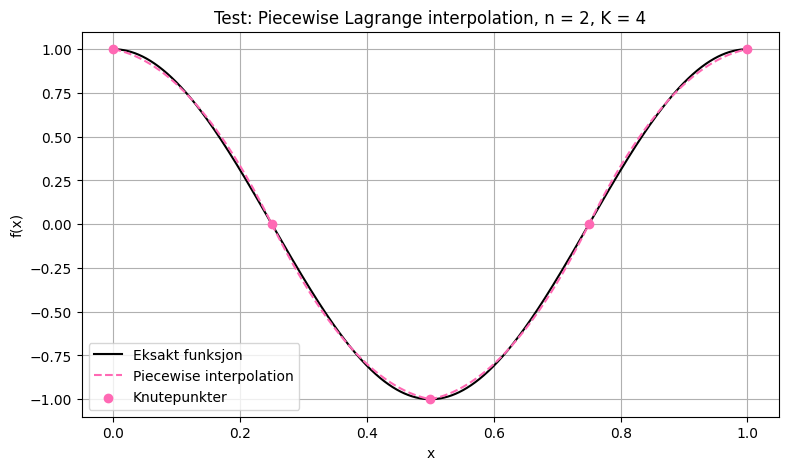

Maksimal feil i knutepunktene: 0.0


In [339]:
#Parametere
a, b = 0, 1
n = 2
K = 4

#Tett grid
x = np.linspace(a, b, 2001)

#Eksakt funksjon og stykkevis interpolasjon
y_exact = f1(x)
P = piecewise_interpolation(f1, a, b, n, K, x)

#Knutepunktene mellom delintervallene
v = np.linspace(a, b, K + 1)

plt.figure(figsize=(9, 5))

plt.plot(x, y_exact, color="black", label="Eksakt funksjon")
plt.plot(x, P, "--", color="hotpink", label="Piecewise interpolation")

plt.scatter(v, f1(v), color="hotpink", zorder=5, label="Knutepunkter")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title(f"Test: Piecewise Lagrange interpolation, n = {n}, K = {K}")
plt.legend()
plt.grid()
plt.show()

#Test at interpolanten treffer funksjonen i knutepunktene
P_knots = piecewise_interpolation(f1, a, b, n, K, v)

print("Maksimal feil i knutepunktene:",
      np.max(np.abs(f1(v) - P_knots)))

### Observasjon – Kontinuitet

Interpolanten treffer funksjonen eksakt i alle knutepunktene, med en målt feil på 0.

Siden endepunktene inngår som interpolasjonsnoder i begge tilstøtende delintervaller, får man

$$
p_n^{(i-1)}(v_i)=f(v_i)=p_n^{(i)}(v_i).
$$

Den samlede interpolanten er derfor kontinuerlig. 

#### Konvergens for n = 1, ..., 10

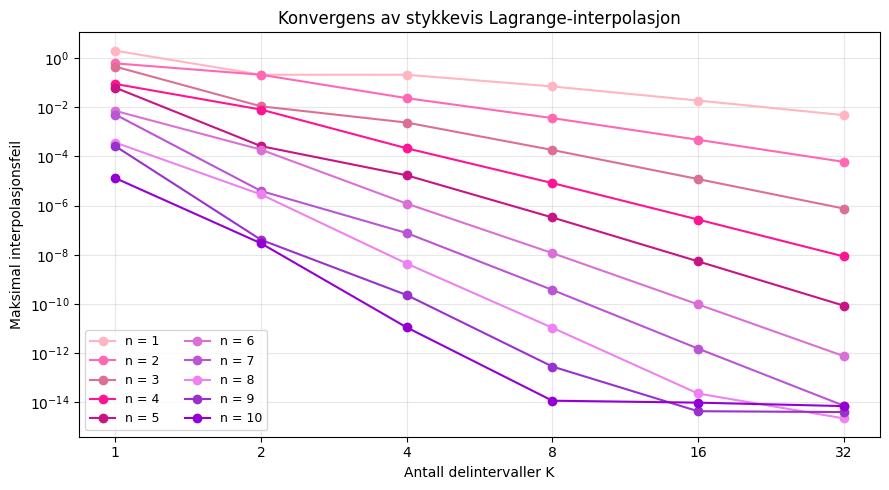

In [340]:
#Testfunksjon og intervall
f = f1 #cos(2pix) fra tidligere oppgave
a, b = 0, 1

#grader og antall delintervaller som skal undersøkes
n_values_c = np.arange(1, 11)
K_values = np.array([1, 2, 4, 8, 16, 32]) 
colors = ["lightpink","hotpink","palevioletred", "deeppink", "mediumvioletred",  "orchid","mediumorchid", "violet", "darkorchid", "darkviolet"]


N = 20000
x = np.linspace(a, b, N + 1)
f_exact = f(x)

#Lagrer maks-feilen for hver kombinasjon av n og K
piecewise_errors = np.zeros((len(n_values_c), len(K_values)))

for i, n in enumerate(n_values_c):
    for j, K in enumerate(K_values):

        #Beregn stykkevis interpolasjon
        P = piecewise_interpolation(f, a, b, n, K, x)

        #Gjenbruk feilfunksjonen fra 1b
        max_error, _ = interpolation_errors(f_exact, P, a, b, N)

        piecewise_errors[i, j] = max_error

#Plot maks-feilen som funksjon av K
plt.figure(figsize=(9, 5))

for i, n in enumerate(n_values_c):
    plt.loglog(K_values, piecewise_errors[i],"-o", label=f"n = {n}",  color=colors[i])

plt.xlabel("Antall delintervaller K")
plt.ylabel("Maksimal interpolasjonsfeil")
plt.title("Konvergens av stykkevis Lagrange-interpolasjon")

#Vis de faktiske K-verdiene på x-aksen
plt.xticks(K_values, K_values)
plt.minorticks_off()

#Gjør rutenettet mindre dominerende
plt.grid(True, which="major", alpha=0.3)

plt.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

**Observasjon:** Interpolasjonsfeilen avtar når antall delintervaller $K$ øker, noe som gir numerisk evidens for konvergens. Høyere polynomgrader gir generelt raskere feilreduksjon. For store $n$ og $K$ flater feilen ut rundt $10^{-14}$, ettersom avrundingsfeil begynner å dominere.


##### Numerisk dokumentasjon av konvergens

In [341]:
#Undersøker representative polynomgrader
for n in [1, 2, 3, 4]:

    i = n - 1
    errors = piecewise_errors[i]

    print(f"\nn = {n}, forventet konvergensorden = {n + 1}")
    print(f"{'K':>6} {'Maks-feil':>15} {'Estimert orden':>18}")

    for j, K in enumerate(K_values):

        #Første verdi har ingen tidligere feil å sammenligne med
        if j == 0:
            print(f"{K:6d} {errors[j]:15.6e} {'-':>18}")
        else:
            #K dobles mellom hvert eksperiment
            order = np.log2(errors[j - 1] / errors[j])

            print(f"{K:6d} {errors[j]:15.6e} {order:18.4f}")


n = 1, forventet konvergensorden = 2
     K       Maks-feil     Estimert orden
     1    2.000000e+00                  -
     2    2.105137e-01             3.2480
     4    2.105137e-01             0.0000
     8    7.037761e-02             1.5807
    16    1.884631e-02             1.9008
    32    4.792099e-03             1.9756

n = 2, forventet konvergensorden = 3
     K       Maks-feil     Estimert orden
     1    6.112735e-01                  -
     2    2.105137e-01             1.5379
     4    2.353688e-02             3.1609
     8    3.636283e-03             2.6944
    16    4.777361e-04             2.9282
    32    6.045428e-05             2.9823

n = 3, forventet konvergensorden = 4
     K       Maks-feil     Estimert orden
     1    4.501285e-01                  -
     2    1.095561e-02             5.3606
     4    2.393242e-03             2.1946
     8    1.836498e-04             3.7039
    16    1.204231e-05             3.9308
    32    7.615708e-07             3.9830

n =

### Numerisk bevis på konvergens

Resultatene viser at stykkevis interpolasjon konvergerer når antall delintervaller $K$ øker, for alle polynomgradene $n=1,\ldots,10$.

For tilstrekkelig glatte funksjoner forventer vi

$$
\|f-P\|_\infty=O(K^{-(n+1)}).
$$

De numeriske resultatene stemmer godt med teorien. Når $K$ øker fra 16 til 32, får vi estimerte konvergensordener på henholdsvis 1.98, 2.98, 3.98 og 4.98 for $n=1,2,3,4$. Dette ligger svært nær de forventede ordenene 2, 3, 4 og 5.

For små verdier av $K$ varierer konvergensordenen mer, ettersom den asymptotiske oppførselen ennå ikke er tydelig.

For høyere polynomgrader når feilen etter hvert maskinpresisjon, omtrent $10^{-15}$. Videre reduksjon av feilen blir da begrenset av avrundingsfeil.

Eksperimentet gir dermed numerisk evidens for konvergens når $K$ øker, frem til maskinpresisjon begrenser resultatene.

##### Sammenligning med global interpolasjon

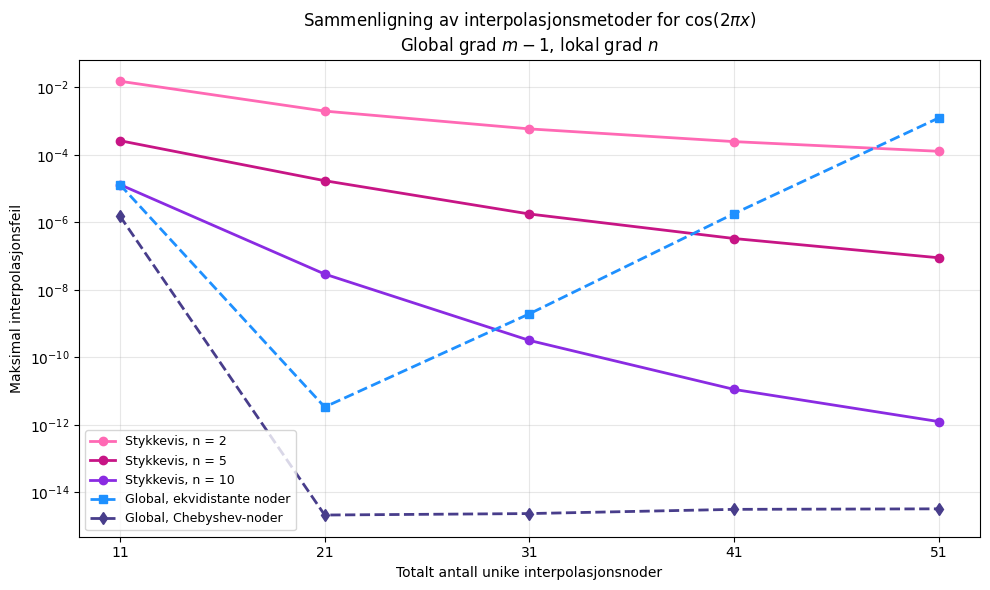

In [342]:
#Testfunksjon og intervall
f_compare = f1 
a_compare, b_compare = 0, 1

#Samme antall unike noder for alle metodene
total_nodes = np.array([11, 21, 31, 41, 51])

#Lokale polynomgrader
local_degrees = [2, 5, 10]


colors_compare = {2: "hotpink",5: "mediumvioletred",10: "blueviolet","eq": "dodgerblue","cheb": "darkslateblue"}


N_compare = 20000
x_compare = np.linspace(a_compare, b_compare, N_compare + 1)
f_exact_compare = f_compare(x_compare)


#Hjelpefunksjon for global interpolasjon
def global_interpolation(f, a, b, m, x, node_function):

    #Et globalt polynom med m noder har grad m - 1
    n_global = m - 1

    x_nodes = node_function(a, b, n_global)
    y_nodes = f(x_nodes)

    return lagrange_interpolation(x_nodes, y_nodes, x)



errors_piecewise = {n: [] for n in local_degrees}
errors_global_eq = []
errors_global_cheb = []


for m in total_nodes:

    #STYKKEVIS INTERPOLASJON
    for n in local_degrees:

        #Beregn antall delintervaller
        K = (m - 1) // n

        P = piecewise_interpolation(f_compare, a_compare, b_compare, n, K, x_compare)

        max_error, _ = interpolation_errors( f_exact_compare, P, a_compare, b_compare, N_compare)

        errors_piecewise[n].append(max_error)


    #GLOBAL INTERPOLASJON: EKVIDISTANTE NODER
    p_eq = global_interpolation(f_compare, a_compare, b_compare, m,x_compare, equidistant_nodes)

    error_eq, _ = interpolation_errors(f_exact_compare, p_eq, a_compare, b_compare, N_compare )

    errors_global_eq.append(error_eq)


    #GLOBAL INTERPOLASJON: CHEBYSHEV-NODER
    p_cheb = global_interpolation(f_compare, a_compare, b_compare, m, x_compare, chebyshev_nodes)

    error_cheb, _ = interpolation_errors(f_exact_compare, p_cheb, a_compare, b_compare, N_compare)

    errors_global_cheb.append(error_cheb)



plt.figure(figsize=(10, 6))

#Stykkevis interpolasjon for tre forskjellige grader
for n in local_degrees:

    plt.semilogy( total_nodes, errors_piecewise[n],"o-",label=f"Stykkevis, n = {n}",color=colors_compare[n],linewidth=2)


# Global interpolasjon
plt.semilogy(total_nodes, errors_global_eq, "s--",label="Global, ekvidistante noder",color=colors_compare["eq"],linewidth=2)

plt.semilogy(total_nodes, errors_global_cheb,"d--",label="Global, Chebyshev-noder",color=colors_compare["cheb"], linewidth=2)


plt.xlabel("Totalt antall unike interpolasjonsnoder")
plt.ylabel("Maksimal interpolasjonsfeil")


plt.title(f'Sammenligning av interpolasjonsmetoder for $\\cos(2\\pi x)$\n'r'Global grad $m-1$, lokal grad $n$')

plt.xticks(total_nodes)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Observasjon – Sammenligning av metodene

Vi sammenligner metodene for samme testfunksjon og totalt antall unike interpolasjonsnoder, $m=11,21,31,41,51$. Ved stykkevis interpolasjon bruker vi lokale polynomgrader $n=2,5,10$, der antall delintervaller $K$ bestemmes av $m=Kn+1$. Ved global interpolasjon bruker vi ett polynom av grad $m-1$.

**Stykkevis interpolasjon** gir en jevn reduksjon i feilen når antall noder øker. Høyere lokal polynomgrad gir også betydelig bedre nøyaktighet ved samme antall noder. For $m=51$ er feilen omtrent $10^{-4}$, $10^{-7}$ og $10^{-12}$ for henholdsvis $n=2$, $n=5$ og $n=10$. Siden den lokale polynomgraden holdes fast, kan vi øke antall noder uten å måtte beregne ett globalt polynom med stadig høyere grad.

**Global interpolasjon med ekvidistante noder** gir først en rask feilreduksjon og når omtrent $10^{-12}$ ved 21 noder. Ved ytterligere økning i antall noder begynner imidlertid feilen å vokse. Dette kan skyldes at den numeriske beregningen av Lagrange-polynomet blir mer følsom ved høy polynomgrad. Store positive og negative ledd kan kansellere hverandre, slik at små avrundingsfeil forsterkes.

For å forstå denne utviklingen skiller vi mellom den matematiske interpolasjonsfeilen og den numeriske beregningsfeilen. Ved trekantulikheten får vi

$$
\underbrace{\|f-\widetilde{p}_n\|_\infty}_{\text{Observert feil}}
\leq
\underbrace{\|f-p_n\|_\infty}_{\text{Interpolasjonsfeil}}
+
\underbrace{\|p_n-\widetilde{p}_n\|_\infty}_{\text{Numerisk beregningsfeil}},
$$

der $p_n$ er det eksakte interpolasjonspolynomet og $\widetilde{p}_n$ er den numerisk beregnede tilnærmingen. For cosinusfunksjonen går den teoretiske interpolasjonsfeilen mot null, men beregningsfeilen kan samtidig øke med polynomgraden. Dette forklarer hvordan den observerte feilen kan vokse selv om den eksakte interpolasjonen konvergerer.

**Global interpolasjon med Chebyshev-noder** gir den raskeste feilreduksjonen i eksperimentet og når omtrent maskinpresisjon allerede ved 21 noder. Deretter flater feilen ut rundt $10^{-15}$. Chebyshev-noder har en mindre Lebesgue-konstant enn ekvidistante noder, noe som gir mindre følsomhet for feil i nodeverdiene og bidrar til mer stabile interpolasjonsberegninger.

Samlet viser resultatene at global Chebyshev-interpolasjon oppnår svært høy nøyaktighet for den glatte cosinusfunksjonen med relativt få noder. Stykkevis interpolasjon gir en jevn feilreduksjon ved å øke antall delintervaller uten å øke den lokale polynomgraden. Global interpolasjon med ekvidistante noder oppnår også høy nøyaktighet ved et moderat antall noder, men viser økende numerisk feil ved høyere polynomgrader. Forskjellene illustrerer at både nodeplassering, polynomgrad og numerisk stabilitet har betydning for den observerte interpolasjonsfeilen.


##### Mål faktiske kjøretider

In [343]:
#Representativt utvalg av K-verdier
K_time = [2, 5, 10, 15, 20, 25]
n_local = 2


x_time = np.linspace(a, b, 2001)

repeats = 5


nodes_time = []
times_piecewise = []
times_global_eq = []
times_global_cheb = []

def measure_time(method, repeats=5):
    #Varmer opp funksjonen før måling
    method()

    measurements = []

    for _ in range(repeats):
        start = time.perf_counter()

        method()

        elapsed = time.perf_counter() - start
        measurements.append(elapsed)

    #Bruk medianen for å redusere påvirkning fra tilfeldige variasjoner
    return np.median(measurements)


for K in K_time:

    #Samme antall unike interpolasjonsnoder for alle metodene
    m = K * n_local + 1
    n_global = m - 1

    nodes_time.append(m)

    #Stykkevis interpolasjon
    t_pw = measure_time(lambda: piecewise_interpolation(f, a, b, n_local, K, x_time), repeats )

    #Global interpolasjon med ekvidistante noder
    def global_eq():
        nodes = equidistant_nodes(a, b, n_global)
        return lagrange_interpolation(nodes, f(nodes), x_time)

    t_eq = measure_time(global_eq, repeats)

    #Global interpolasjon med Chebyshev-noder
    def global_cheb():
        nodes = chebyshev_nodes(a, b, n_global)
        return lagrange_interpolation(nodes, f(nodes), x_time)

    t_cheb = measure_time(global_cheb, repeats)

    times_piecewise.append(t_pw)
    times_global_eq.append(t_eq)
    times_global_cheb.append(t_cheb)

#Skriv ut målingene i en tabell
print(f"{'Noder':>8} {'Piecewise (ms)':>18} "
      f"{'Global eq (ms)':>18} {'Global Cheb (ms)':>20}")

for i, m in enumerate(nodes_time):
    print(f"{m:8d} "
          f"{times_piecewise[i]*1000:18.4f} "
          f"{times_global_eq[i]*1000:18.4f} "
          f"{times_global_cheb[i]*1000:20.4f}")

   Noder     Piecewise (ms)     Global eq (ms)     Global Cheb (ms)
       5             0.1326             0.1103               0.1096
      11             0.2422             0.5513               0.5034
      21             0.4490             1.7045               1.8474
      31             0.6911             4.1680               3.9772
      41             0.9799             6.7410               6.9410
      51             1.0582            10.9930              10.8823


#### Plotter kjøretidene

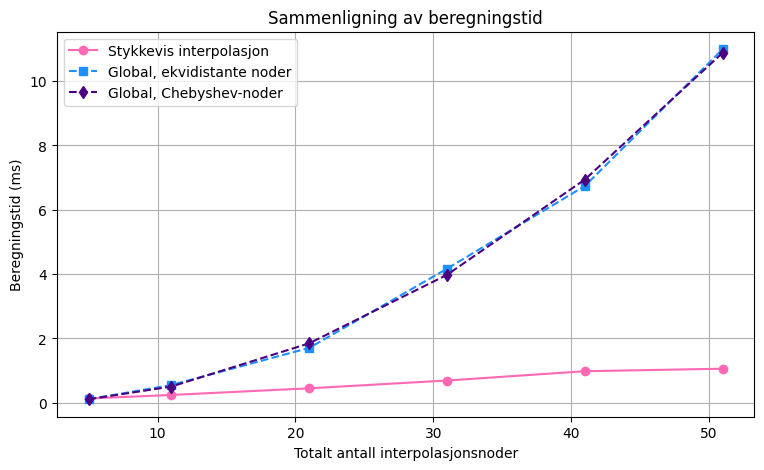

In [363]:
plt.figure(figsize=(9, 5))

# Konverter sekunder til millisekunder
plt.plot(nodes_time, np.array(times_piecewise) * 1000, "o-", label="Stykkevis interpolasjon", color="hotpink")

plt.plot(nodes_time, np.array(times_global_eq) * 1000, "s--", label="Global, ekvidistante noder", color="dodgerblue")

plt.plot(nodes_time, np.array(times_global_cheb) * 1000, "d--", label="Global, Chebyshev-noder", color="indigo")

plt.xlabel("Totalt antall interpolasjonsnoder")
plt.ylabel("Beregningstid (ms)")
plt.title("Sammenligning av beregningstid")
plt.legend()
plt.grid()
plt.show()

### Diskusjon – Beregningskostnad og metodevalg

#### Beregningskostnad


For den direkte Lagrange-implementasjonen krever evaluering av et globalt polynom med $m$ noder på $N+1$ punkter omtrent

$$
O(Nm^2)
$$

aritmetiske operasjoner.

Ved stykkevis interpolasjon bruker man polynomer av fast grad $n$. Evalueringen av disse krever omtrent

$$
O(Nn^2)
$$

operasjoner. Implementasjonen går også gjennom hele evalueringsgridet for hvert av de $K$ delintervallene, noe som gir en ekstra kostnad på $O(KN)$.

De målte kjøretidene viser at stykkevis interpolasjon blir raskere enn global interpolasjon når antall noder øker.

Med 5 noder er global interpolasjon raskest med 0.1096 og 0.1103 mot stykkevis med 0.133. Med 31 noder bruker derimot den stykkevise metoden omtrent 0.69 ms, sammenlignet med 4.17 ms for global interpolasjon med ekvidistante noder og 3.98 ms for Chebyshev-noder.

Den stykkevise metoden er dermed omtrent 4–5 ganger raskere i dette tilfellet.

Målingene viser også enkelte variasjoner, ettersom kjøretidene er svært korte og kan påvirkes av systembelastning og måleusikkerhet.

#### Fordeler og ulemper

Global interpolasjon representerer hele funksjonen med ett polynom. For glatte funksjoner kan metoden gi svært høy nøyaktighet med relativt få noder, spesielt ved bruk av Chebyshev-noder. Ulempen er at polynomgraden øker med antall noder. Dette øker beregningskostnaden i vår direkte implementasjon og kan føre til numeriske problemer. Ekvidistante noder kan også gi Runge-fenomenet, slik vi observerte i oppgave 1a.

Stykkevis interpolasjon holder polynomgraden lav og forbedrer nøyaktigheten ved å dele intervallet i flere deler. Metoden gir en kontinuerlig interpolant og gjør det mulig å arbeide lokalt på hvert delintervall. Ulempen er at vi må håndtere flere polynomer, og at de deriverte ikke nødvendigvis er kontinuerlige i knutepunktene. 

#### Anbefaling

For den glatte testfunksjonen $f(x)=\cos(2\pi x)$ ville jeg valgt global interpolasjon med Chebyshev-noder dersom høy nøyaktighet er viktigst. Med 21 noder oppnår denne metoden en feil på omtrent $2.00\cdot10^{-15}$, mens stykkevis interpolasjon gir omtrent $1.98\cdot10^{-3}$.

Dersom beregningstid er viktig, særlig når mange noder er nødvendige, kan stykkevis interpolasjon være mer hensiktsmessig. Ved 31 noder var denne metoden omtrent 4–5 ganger raskere enn de globale metodene i vår implementasjon.

Stykkevis interpolasjon er også aktuell for funksjoner som varierer mye lokalt, eller når vi ønsker å unngå globale polynomer med høy grad.

Valget av metode avhenger derfor av funksjonens egenskaper og kravene til nøyaktighet og beregningstid. Utregningene viser, for denne testfunksjonen, at global interpolasjon med Chebyshev-noder gir høyest nøyaktighet, mens stykkevis interpolasjon har lavere beregningskostnad når antall noder øker.


## 1d)

##### RBF-interpolasjon

In [345]:
def rbf_interpolation(x_nodes, y_nodes, x, epsilon):
    #Gjør input om til arrays
    x_nodes = np.asarray(x_nodes)
    y_nodes = np.asarray(y_nodes)
    x = np.asarray(x)

    #Beregn avstandene mellom alle interpolasjonsnodene
    distances = x_nodes[:, None] - x_nodes[None, :]

    #Konstruer interpolasjonsmatrisen M
    M = np.exp(-(epsilon * distances)**2)


    w = np.linalg.solve(M, y_nodes)

    #Beregn avstandene mellom evalueringspunktene og nodene
    distances_eval = x[..., None] - x_nodes

    #Evaluer basisfunksjonene i alle ønskede punkter
    Phi = np.exp(-(epsilon * distances_eval)**2)

    #Beregn interpolanten som summen av de vektede basisfunksjonene
    return Phi @ w

##### Test av interpolasjonsbteingelsene

In [346]:
a, b = -5, 5
n = 10
epsilon = 1.0

#Gjenbruk funksjonene fra oppgave 1a
x_nodes = equidistant_nodes(a, b, n)
y_nodes = runge(x_nodes)

#Evaluer RBF-interpolanten i selve nodene
y_rbf = rbf_interpolation(x_nodes, y_nodes, x_nodes, epsilon)

#Beregn maksimal feil i interpolasjonsnodene
node_error = np.max(np.abs(y_nodes - y_rbf))

print(f"Maksimal feil i nodene: {node_error:.6e}")

Maksimal feil i nodene: 1.110223e-16


##### Tester på Runge funksjonen

epsilon = 0.40, maksimal feil = 1.256381e-01
epsilon = 0.60, maksimal feil = 3.911251e-02
epsilon = 0.80, maksimal feil = 3.272434e-02
epsilon = 1.00, maksimal feil = 2.571113e-02
epsilon = 1.20, maksimal feil = 8.865345e-03
epsilon = 1.26, maksimal feil = 1.591808e-03
epsilon = 1.50, maksimal feil = 5.423175e-02
epsilon = 2.00, maksimal feil = 2.635773e-01


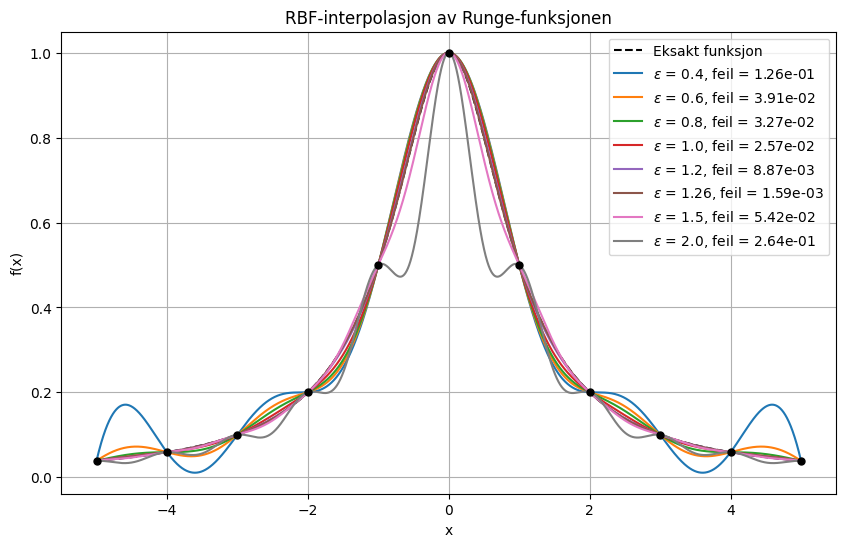

In [347]:
a, b = -5, 5
n = 10

#Interpolasjonsnoder
x_nodes = equidistant_nodes(a, b, n)
y_nodes = runge(x_nodes)

#Tett grid for evaluering og feilberegning
x = np.linspace(a, b, 3001)
y_exact = runge(x)

epsilon_values = [0.4, 0.6, 0.8, 1.0, 1.2, 1.26, 1.5, 2.0]

plt.figure(figsize=(10, 6))

#Plott den eksakte funksjonen og nodene
plt.plot(x, y_exact, "k--", label="Eksakt funksjon")
plt.scatter(x_nodes, y_nodes, color="black", s=25, zorder=5)

#Test ulike verdier av epsilon
for epsilon in epsilon_values:

    # Beregn RBF-interpolanten
    y_rbf = rbf_interpolation(x_nodes, y_nodes, x, epsilon)

    # Beregn maksimal interpolasjonsfeil
    max_error = np.max(np.abs(y_exact - y_rbf))

    # Plott interpolanten
    plt.plot(x, y_rbf,
             label=fr"$\varepsilon$ = {epsilon}, feil = {max_error:.2e}")

    print(f"epsilon = {epsilon:.2f}, maksimal feil = {max_error:.6e}")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("RBF-interpolasjon av Runge-funksjonen")
plt.legend()
plt.grid(True)
plt.show()

epsilon = 1.0, maksimal feil = 1.018844e-06
epsilon = 2.0, maksimal feil = 6.504456e-06
epsilon = 3.0, maksimal feil = 4.179313e-04
epsilon = 5.0, maksimal feil = 2.624787e-03
epsilon = 8.0, maksimal feil = 3.973950e-02


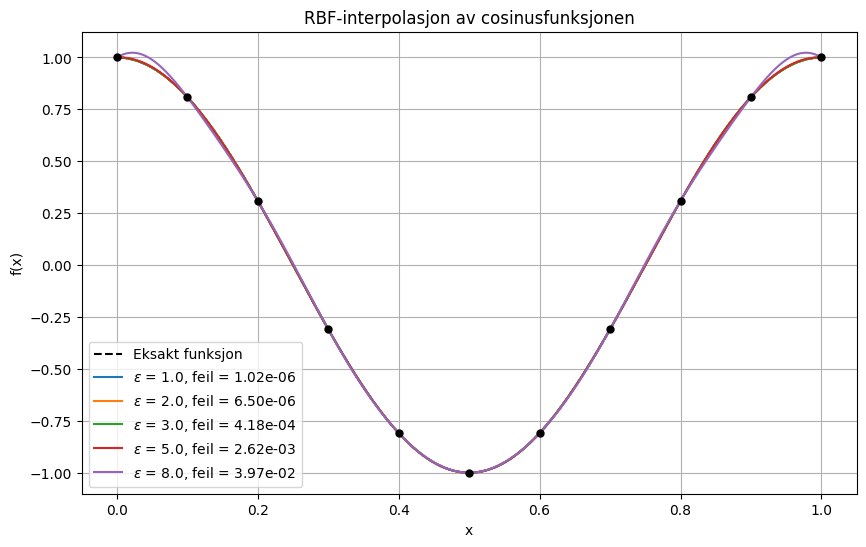

In [348]:
a, b = 0, 1
n = 10

# Interpolasjonsnoder
x_nodes = equidistant_nodes(a, b, n)
y_nodes = f1(x_nodes)

#Tett grid
x = np.linspace(a, b, 3001)
y_exact = f1(x)

#Verdier av epsilon
epsilon_values = [1.0, 2.0, 3.0, 5.0, 8.0]

plt.figure(figsize=(10, 6))

plt.plot(x, y_exact, "k--", label="Eksakt funksjon")
plt.scatter(x_nodes, y_nodes, color="black", s=25, zorder=5)

for epsilon in epsilon_values:

    try:
        # Beregn RBF-interpolanten
        y_rbf = rbf_interpolation(x_nodes, y_nodes, x, epsilon)

        # Beregn maksimal feil
        max_error = np.max(np.abs(y_exact - y_rbf))

        plt.plot(x, y_rbf, label=fr"$\varepsilon$ = {epsilon}, feil = {max_error:.2e}")

        print(f"epsilon = {epsilon:.1f}, maksimal feil = {max_error:.6e}")

    except np.linalg.LinAlgError:
        print(f"epsilon = {epsilon:.1f}: Matrisen er numerisk singulær.")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("RBF-interpolasjon av cosinusfunksjonen")
plt.legend()
plt.grid(True)
plt.show()

##### Kondisjonstall og interpolasjonsfeil

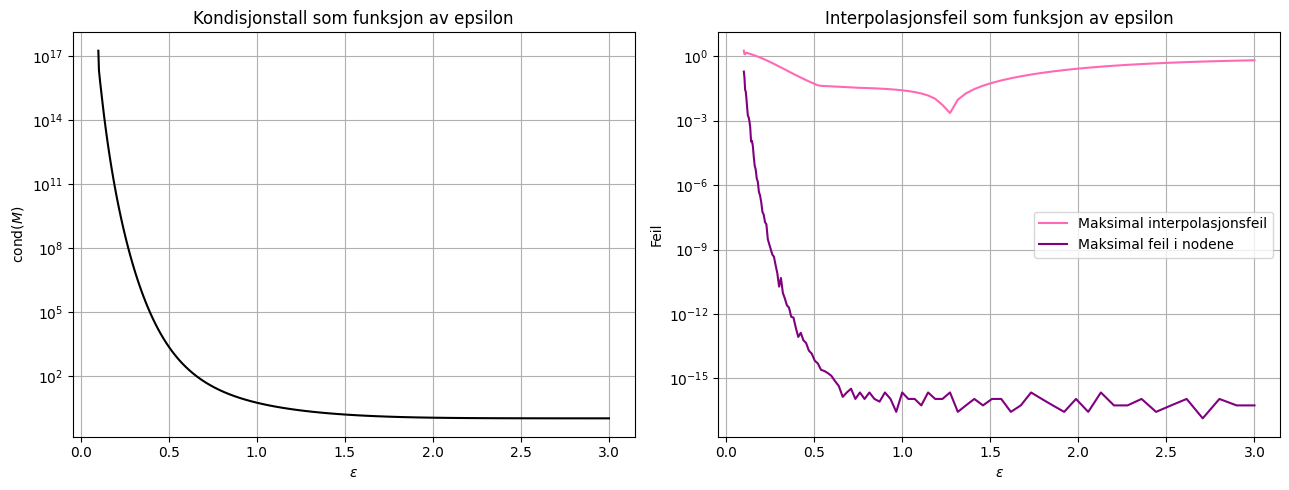

In [349]:

a, b = -5, 5
n = 10

x_nodes = equidistant_nodes(a, b, n)
y_nodes = runge(x_nodes)

x = np.linspace(a, b, 3001)
y_exact = runge(x)

#Undersøk et bredt intervall av epsilon
epsilon_values = np.logspace(-1, np.log10(3), 100) #begrunn valg

condition_numbers = []
max_errors = []
node_errors = []

for epsilon in epsilon_values:

    #Konstruer interpolasjonsmatrisen
    distances = x_nodes[:, None] - x_nodes[None, :]
    M = np.exp(-(epsilon * distances)**2)

    #Beregn kondisjonstallet
    condition_numbers.append(np.linalg.cond(M))

    try:
        #Beregn RBF-interpolanten på det tette gridet
        y_rbf = rbf_interpolation(x_nodes, y_nodes, x, epsilon)

        #Maksimal feil mellom eksakt funksjon og interpolant
        max_errors.append(np.max(np.abs(y_exact - y_rbf)))

        #Kontroller interpolasjonsbetingelsene i nodene
        y_rbf_nodes = rbf_interpolation( x_nodes, y_nodes, x_nodes, epsilon )
        node_errors.append(np.max(np.abs(y_nodes - y_rbf_nodes)))

    except np.linalg.LinAlgError:
        max_errors.append(np.nan)
        node_errors.append(np.nan)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].semilogy(epsilon_values, condition_numbers, color="black")
axes[0].set_xlabel(r"$\varepsilon$")
axes[0].set_ylabel(r"$\mathrm{cond}(M)$")
axes[0].set_title("Kondisjonstall som funksjon av epsilon")
axes[0].grid(True)

axes[1].semilogy(epsilon_values, max_errors, label="Maksimal interpolasjonsfeil", color="hotpink")
axes[1].semilogy(epsilon_values, node_errors, label="Maksimal feil i nodene", color="purple")

axes[1].set_xlabel(r"$\varepsilon$")
axes[1].set_ylabel("Feil")
axes[1].set_title("Interpolasjonsfeil som funksjon av epsilon")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Tester $\varepsilon$ i intervallet $[0.1,3]$ på en logaritmisk skala. Små verdier tas med for å undersøke når matrisen $M$ blir dårlig kondisjonert, mens større verdier gjør det mulig å se hvordan interpolasjonsfeilen utvikler seg når RBF-ene blir smalere. Intervallet er valgt slik at både området med dårlig kondisjonering og området med god numerisk stabilitet kommer tydelig frem i plottet.

#### Numeriske observasjoner

In [350]:
# Runge-funksjonen med n = 10
a, b = -5, 5
n = 10

x_nodes = equidistant_nodes(a, b, n)
y_nodes = runge(x_nodes)

x = np.linspace(a, b, 3001)
y_exact = runge(x)

# Representative verdier for stabilitet og nøyaktighet
epsilon_test = [0.1, 0.15, 0.2, 0.3, 0.4, 1.0, 1.2, 1.26, 1.5, 2.0]

print(f"{'epsilon':>10} {'cond(M)':>15} " f"{'Maks-feil':>15} {'Nodefeil':>15}")

for epsilon in epsilon_test:

    # Konstruer RBF-matrisen
    D = x_nodes[:, None] - x_nodes[None, :]
    M = np.exp(-(epsilon * D)**2)

    # Kondisjonstall
    cond_M = np.linalg.cond(M)

    try:
        # Interpolasjon på det tette gridet
        y_rbf = rbf_interpolation( x_nodes, y_nodes, x, epsilon)

        # Interpolasjon i nodene
        y_rbf_nodes = rbf_interpolation( x_nodes, y_nodes, x_nodes, epsilon)

        # Beregn begge feilene
        max_error = np.max(np.abs(y_exact - y_rbf))
        node_error = np.max(np.abs(y_nodes - y_rbf_nodes))

        print(f"{epsilon:10.2f} {cond_M:15.3e} " f"{max_error:15.3e} {node_error:15.3e}")

    except np.linalg.LinAlgError:
        print(f"{epsilon:10.2f}: Matrisen er numerisk singulær.")

   epsilon         cond(M)       Maks-feil        Nodefeil
      0.10       1.819e+17       1.793e+00       1.912e-01
      0.15       1.288e+13       1.163e+00       3.433e-05
      0.20       3.827e+10       8.122e-01       2.071e-07
      0.30       1.283e+07       3.315e-01       2.910e-11
      0.40       7.111e+04       1.256e-01       2.046e-13
      1.00       5.426e+00       2.571e-02       1.110e-16
      1.20       2.671e+00       8.865e-03       2.220e-16
      1.26       2.299e+00       1.592e-03       2.220e-16
      1.50       1.511e+00       5.423e-02       1.110e-16
      2.00       1.073e+00       2.636e-01       2.776e-17


## Diskusjon

### 1. Interpolasjonsbetingelsene

RBF-interpolasjonen ble implementert ved å løse ligningssystemet $M\mathbf{w}=\mathbf{y}$. For Runge-funksjonen med $n=10$ og $\varepsilon=1$ fikk man en maksimal feil i interpolasjonsnodene på $1.11\cdot10^{-16}$. Dette er omtrent maskinpresisjon og bekrefter at implementasjonen oppfyller interpolasjonsbetingelsene svært nøyaktig for disse parameterne.

### 2. Runge-funksjonen

Resultatene viser at approksimasjonsfeilen er svært avhengig av formparameteren $\varepsilon$. Ved $\varepsilon=0.4$ er maksimalfeilen $0.126$, og interpolanten viser tydelige svingninger nær endepunktene. Når $\varepsilon$ økes til $1.0$, reduseres feilen til $0.0257$.

En finere undersøkelse gir en maksimalfeil på omtrent $0.00159$ ved $\varepsilon=1.26$, som er omtrent 16 ganger lavere enn ved $\varepsilon=1.0$. Dette er den minste feilen blant parameterverdiene vi undersøkte.

For større verdier blir approksimasjonen dårligere igjen. Ved $\varepsilon=2.0$ øker maksimalfeilen til $0.264$. Dette skyldes at basisfunksjonene blir smalere og får mindre overlapp, slik at interpolanten får tydelige avvik mellom nodene.

Vi observerer dermed at verken svært små eller svært store verdier av $\varepsilon$ gir den beste tilnærmingen til Runge-funksjonen.

### 3. Cosinusfunksjonen

For $f(x)=\cos(2\pi x)$ på $[0,1]$ oppnår man en maksimalfeil på $1.02\cdot10^{-6}$ ved $\varepsilon=1.0$. Interpolanten er dermed nesten umulig å skille fra den eksakte funksjonen i plottet.

Når $\varepsilon$ økes til $8.0$, stiger maksimalfeilen til $0.0397$. Man ser blant annet at interpolanten får tydelige avvik nær endepunktene.

Resultatene viser at et passende valg av $\varepsilon$ avhenger av både funksjonen og intervallet. Verdien som fungerer godt for Runge-funksjonen, kan derfor ikke uten videre overføres til cosinusfunksjonen.

### 4. Kondisjonstall og numerisk stabilitet

Kondisjonstallet $\kappa(M)$ øker kraftig når $\varepsilon$ reduseres. For Runge-funksjonen får man $\kappa(M)\approx1.819\cdot10^{17}$ ved $\varepsilon=0.1$. Samtidig er feilen i interpolasjonsnodene omtrent $0.1912$, noe som viser at den beregnede interpolanten ikke lenger oppfyller interpolasjonsbetingelsene med tilfredsstillende nøyaktighet.

Ved $\varepsilon=0.15$ er kondisjonstallet omtrent $1.29\cdot10^{13}$, og nodefeilen er fortsatt $3.433\cdot10^{-5}$. Allerede ved $\varepsilon=0.2$ er matrisen svært dårlig kondisjonert, med $\kappa(M)\approx3.83\cdot10^{10}$. Når vi øker til $\varepsilon=0.4$, reduseres kondisjonstallet til omtrent $7.11\cdot10^4$, og nodefeilen blir $2.046\cdot10^{-13}$.

Matrisen er dermed svært dårlig kondisjonert for $\varepsilon\lesssim0.2$. Ved $\varepsilon=0.15$ og lavere begynner dette også å gi tydelige numeriske feil i interpolasjonsbetingelsene. Vi betrakter derfor dette området som numerisk upålitelig for denne beregningen, selv om den nøyaktige grensen avhenger av hvilket nøyaktighetskrav man stiller.

Det er også viktig å skille mellom kondisjonering og approksimasjonsfeil. Ved $\varepsilon=0.4$ oppfylles interpolasjonsbetingelsene svært nøyaktig, med en nodefeil på omtrent $2.05\cdot10^{-13}$, mens maksimalfeilen mellom nodene fortsatt er $0.126$. At interpolasjonsbetingelsene oppfylles nøyaktig garanterer derfor ikke at interpolanten gir en god approksimasjon mellom nodene.

#### Ytterligere observasjoner om stabilitet

For cosinusfunksjonen oppnår man den minste observerte maksimalfeilen ved $\varepsilon=1.0$, men kondisjonstallet er da omtrent $8.92\cdot10^{16}$. Dette innebærer at ligningssystemet er svært følsomt for numeriske feil, selv om den beregnede interpolanten gir en god tilnærming.

Ved $\varepsilon=2.0$ reduseres kondisjonstallet til omtrent $3.83\cdot10^{10}$, mens maksimalfeilen bare øker fra $1.02\cdot10^{-6}$ til $6.50\cdot10^{-6}$. Dette illustrerer hvordan man kan oppnå bedre kondisjonering ved å akseptere en noe større approksimasjonsfeil, selv om matrisen fortsatt er dårlig kondisjonert.

For Runge-funksjonen er situasjonen annerledes. Ved $\varepsilon=1.26$ får man både den minste observerte maksimalfeilen, $1.59\cdot10^{-3}$, og et lavt kondisjonstall på omtrent $2.30$. Denne parameterverdien gir dermed både god approksimasjonsnøyaktighet og numerisk stabilitet i forsøket vårt.

### 5. Konklusjon

Resultatene viser at valg av $\varepsilon$ påvirker både approksimasjonsnøyaktigheten og den numeriske stabiliteten. For svært små $\varepsilon$ overlapper basisfunksjonene kraftig, og interpolasjonsmatrisen blir nær singulær. Dette forsterker avrundingsfeil. For store $\varepsilon$ blir basisfunksjonene smale, og approksimasjonen mellom nodene blir dårligere.

For Runge-funksjonen finnes det derfor et mellomområde som gir best resultat. Blant verdiene vi undersøkte ga $\varepsilon=1.26$ den minste maksimalfeilen, omtrent $1.59\cdot10^{-3}$, samtidig som kondisjonstallet var lavt, $\kappa(M)\approx2.30$. Denne verdien gir dermed både god approksimasjonsnøyaktighet og god numerisk stabilitet i forsøket.

## 1e)

In [351]:
import autograd.numpy as anp
from autograd import grad

#Testfunksjon og intervall fra oppgave 1d
f = runge
a, b = -5, 5

#Antall interpolasjonsnoder er n + 1
n = 10

#Tett grid for kostnadsfunksjonen
N = 1000
eta = np.linspace(a, b, N + 1)
c = f(eta)

#Initialverdier: ekvidistante noder og epsilon fra 1d
x0 = equidistant_nodes(a, b, n)
epsilon0 = 1.26

#Samle alle variablene i én vektor
z0 = np.append(x0, epsilon0)

##### Kostandsfunksjonen

In [352]:
def cost_function(z):
    #Hent ut interpolasjonsnodene og epsilon
    x_nodes = z[:-1]
    epsilon = z[-1]

    y_nodes = 1 / (1 + x_nodes**2)

    #RBF-matrisen: kvadrerte avstander 
    D = x_nodes[:, None] - x_nodes[None, :]
    M = anp.exp(-epsilon**2 * D**2)

    #Beregner vektene 
    w = anp.linalg.solve(M, y_nodes)

    #Evaluer RBF på det tette gridet
    D_eval = eta[:, None] - x_nodes[None, :]
    Phi = anp.exp(-epsilon**2 * D_eval**2)

    f_rbf = anp.dot(Phi, w)

    #Least-squares-kostnadsfunksjonen
    error = c - f_rbf

    return (b - a) / N * anp.sum(error**2)

##### Beregner og kontrollerer gradienten

In [353]:
#Lag en funksjon som beregner gradienten automatisk
gradient = grad(cost_function)

#Beregn initial kostnad og gradient
C0 = cost_function(z0)
g0 = gradient(z0)

print(f"Initial kostnad: {C0:.6e}")
print(f"Gradientnorm: {np.linalg.norm(g0):.6e}")

#Kontroller at gradienten ikke inneholder NaN eller inf
assert np.all(np.isfinite(g0)), "Gradienten inneholder NaN eller inf!"

print("Gradienten er gyldig.")

Initial kostnad: 5.545683e-06
Gradientnorm: 1.578848e-04
Gradienten er gyldig.


##### Gradient decent med backtracking

In [354]:
def gradient_descent(z0, L0=1.0, tol=1e-7, max_iter=3000,
                     rho_up=2.0, rho_down=0.9, cond_limit=1e12):

    #Initialiser
    z = np.array(z0, dtype=float)
    C = float(cost_function(z))
    history = [C]

    #Initial verdi av L
    L = L0

    for k in range(max_iter):

        #Beregner gradienten
        g = np.asarray(gradient(z))

        if not np.all(np.isfinite(g)):
            print("Ugyldig gradient. Stopper.")
            break

        #Projisert gradient for stoppkriteriet
        z_projected = z - g
        z_projected[:-1] = np.clip(z_projected[:-1], a, b)
        z_projected[-1] = max(z_projected[-1], 1e-6)

        projected_grad = z - z_projected

        if np.linalg.norm(projected_grad) < tol:
            print(f"Konvergens etter {k} iterasjoner.")
            break

        accepted = False

        #Backtracking
        for j in range(40):

            #steget i appendikset
            z_new = z - (1.0 / L) * g

            #Projiser nodene tilbake til [a,b]
            z_new[:-1] = np.clip(z_new[:-1], a, b)

            #epsilon må være positiv
            z_new[-1] = max(z_new[-1], 1e-6)

            x_new = z_new[:-1]
            epsilon_new = z_new[-1]

            #Krev distinkte og sorterte noder
            valid = np.all(np.diff(x_new) > 1e-5)

            if valid:
                D = x_new[:, None] - x_new[None, :]
                M = np.exp(-epsilon_new**2 * D**2)

                valid = np.linalg.cond(M) < cond_limit

            if valid:
                C_new = float(cost_function(z_new))

                step = z_new - z

                #Backtracking-betingelsen fra appendikset
                rhs = C + np.dot(g, step) + (L / 2.0) * np.linalg.norm(step)**2

                if np.isfinite(C_new) and C_new <= rhs:
                    accepted = True
                    break

            #Steget var for stort, øk L
            L *= rho_up

        if not accepted:
            print(f"Ingen akseptabel steglengde ved iterasjon {k}.")
            break

        #Godta steget
        z = z_new
        C = C_new
        history.append(C)

        #Reduser L litt før neste iterasjon,
        #slik at algoritmen kan prøve et større steg
        L *= rho_down

    else:
        print("Maksimalt antall iterasjoner nådd.")

    return z, np.array(history)

##### testcelle


--- Initial L = 1.0 ---
Maksimalt antall iterasjoner nådd.
Sluttkostnad: 2.376464e-06
Antall iterasjoner: 3000

--- Initial L = 10.0 ---
Maksimalt antall iterasjoner nådd.
Sluttkostnad: 2.404549e-06
Antall iterasjoner: 3000

--- Initial L = 100.0 ---
Maksimalt antall iterasjoner nådd.
Sluttkostnad: 2.403222e-06
Antall iterasjoner: 3000


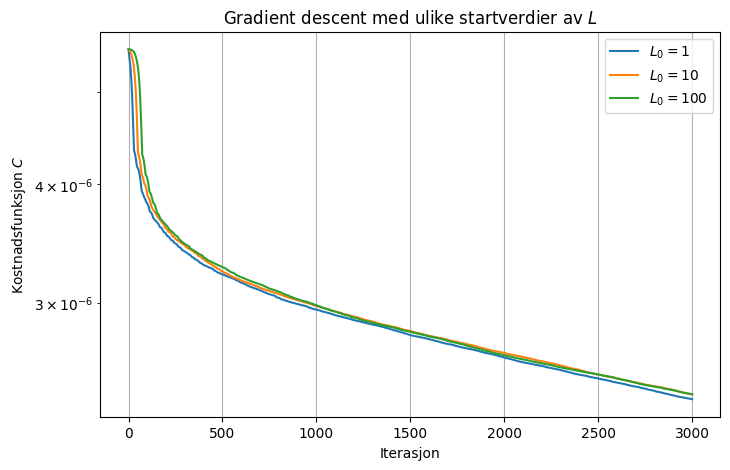

In [355]:
L_values = [1.0, 10.0, 100.0]

results_L = {}

for L0 in L_values:

    print(f"\n--- Initial L = {L0} ---")

    z_test, history_test = gradient_descent(z0, L0=L0,max_iter=3000)

    results_L[L0] = (z_test, history_test)

    print(f"Sluttkostnad: {history_test[-1]:.6e}")
    print(f"Antall iterasjoner: {len(history_test)-1}")


plt.figure(figsize=(8, 5))

for L0 in L_values:
    _, history_test = results_L[L0]

    plt.semilogy(history_test,label=f"$L_0={L0:g}$")

plt.xlabel("Iterasjon")
plt.ylabel("Kostnadsfunksjon $C$")
plt.title("Gradient descent med ulike startverdier av $L$")
plt.legend()
plt.grid(True)
plt.show()

De anbefalte startverdiene $L_0=1,10,100$ ble testet. Alle tre nådde maksimal iterasjonsgrense, men $L_0=1$ ga lavest sluttkostnad og ble derfor brukt videre.

##### Kjører optimaliseringen

In [356]:
#Optimaliser nodene og epsilon
z_opt, history = results_L[1.0]

x_opt = z_opt[:-1]
epsilon_opt = z_opt[-1]

#Beregn tilhørende 2-normer
initial_error = np.sqrt(history[0])
optimal_error = np.sqrt(history[-1])

print(f"Initial epsilon: {epsilon0:.6f}")
print(f"Optimalisert epsilon: {epsilon_opt:.6f}")

print(f"\nInitial 2-norm: {initial_error:.6e}")
print(f"Optimalisert 2-norm: {optimal_error:.6e}")

print("\nOptimaliserte noder:")
print(x_opt)

Initial epsilon: 1.260000
Optimalisert epsilon: 1.273130

Initial 2-norm: 2.354927e-03
Optimalisert 2-norm: 1.541578e-03

Optimaliserte noder:
[-5.00000000e+00 -3.93827259e+00 -2.96471699e+00 -1.97759876e+00
 -9.82751754e-01  1.10114592e-06  9.82751134e-01  1.97759890e+00
  2.96471696e+00  3.93827259e+00  5.00000000e+00]


In [357]:
print("Gradientnorm:", np.linalg.norm(gradient(z_opt)))
print("Antall iterasjoner:", len(history) - 1)
print("Kondisjonstall:", np.linalg.cond(np.exp(-epsilon_opt**2 *(x_opt[:, None] - x_opt[None, :])**2)))

Gradientnorm: 9.762865643607245e-06
Antall iterasjoner: 3000
Kondisjonstall: 2.3051533339798027


##### Plott konvergens historikken

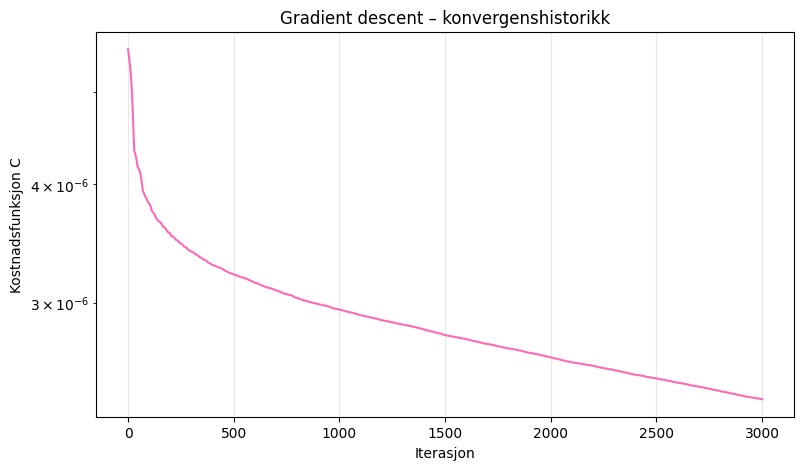

Kostnadsfunksjonen er synkende.


In [358]:
plt.figure(figsize=(9, 5))

plt.semilogy(history, color="hotpink")

plt.xlabel("Iterasjon")
plt.ylabel("Kostnadsfunksjon C")
plt.title("Gradient descent – konvergenshistorikk")

plt.grid(True, alpha=0.3)
plt.show()

# Kontroller at alle aksepterte steg reduserte kostnaden
assert np.all(np.diff(history) <= 1e-12)


print("Kostnadsfunksjonen er synkende.")

assert len(history) > 1, "Ingen optimaliseringssteg ble gjennomført."

##### sammenligner interpolantene visuelt

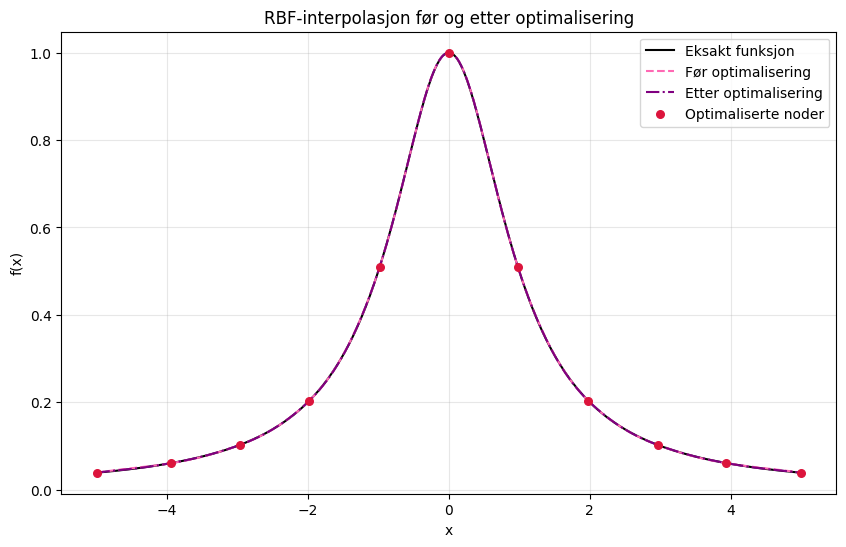

In [359]:
#Beregn interpolantene på det tette gridet
y_initial = rbf_interpolation(x0, f(x0), eta, epsilon0)

y_opt = rbf_interpolation(x_opt, f(x_opt), eta, epsilon_opt)

plt.figure(figsize=(10, 6))

plt.plot(eta, c, "k-", label="Eksakt funksjon")
plt.plot(eta, y_initial, "--", label="Før optimalisering", color="hotpink")
plt.plot(eta, y_opt, "-.", label="Etter optimalisering", color="purple")

#Marker optimaliserte noder
plt.scatter(x_opt, f(x_opt), color="crimson",
            s=30, label="Optimaliserte noder", zorder=5)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("RBF-interpolasjon før og etter optimalisering")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

##### Sammenligningsfunksjon

In [360]:
def rbf_error_2(x_nodes, epsilon):

    y_rbf = rbf_interpolation(x_nodes, f(x_nodes), eta, epsilon)

    #approximation error
    error = c - y_rbf

    #L2 norm
    return np.sqrt((b - a) / N * np.sum(error**2))

##### Beregner og sammenligner funksjonene

In [361]:

n_values = [4, 6, 8, 10]

errors_opt = []
errors_eq = []
errors_cheb = []

epsilon_values = []

for n_test in n_values:

    #ekvidistante noder
    x_initial = equidistant_nodes(a, b, n_test)
    z_initial = np.append(x_initial, epsilon0)

    #Optimiere noder og shape parametere
    z_optimal, history_n = gradient_descent(z_initial, max_iter=3000)

    x_optimal = z_optimal[:-1]
    eps_optimal = z_optimal[-1]

    epsilon_values.append(eps_optimal)

    #Ekvidistante noder
    x_eq = equidistant_nodes(a, b, n_test)

    #Chebyshev noder mapped til [a,b]
    j = np.arange(n_test + 1)

    x_cheb = (a + b)/2 + (b - a)/2 * np.cos( (2*j + 1)*np.pi / (2*(n_test + 1)))

    x_cheb = np.sort(x_cheb)

    #L2 errors
    errors_opt.append(rbf_error_2(x_optimal, eps_optimal))

    errors_eq.append(rbf_error_2(x_eq, eps_optimal) )

    errors_cheb.append(rbf_error_2(x_cheb, eps_optimal))


print("\nSammenligning av L2 feil:\n")

print(f"{'n':<6}{'Optimalisert':<16}{'Ekvidistant':<16}{'Chebyshev':<16}")

for i, n_test in enumerate(n_values):
    print(
        f"{n_test:<6}"
        f"{errors_opt[i]:<16.6e}"
        f"{errors_eq[i]:<16.6e}"
        f"{errors_cheb[i]:<16.6e}"
    )

Maksimalt antall iterasjoner nådd.
Maksimalt antall iterasjoner nådd.
Maksimalt antall iterasjoner nådd.
Maksimalt antall iterasjoner nådd.

Sammenligning av L2 feil:

n     Optimalisert    Ekvidistant     Chebyshev       
4     3.489153e-02    1.625667e-01    2.299562e-01    
6     1.225813e-02    5.326695e-02    1.924868e-01    
8     4.686889e-03    1.041223e-02    1.428983e-01    
10    1.541578e-03    3.242904e-03    1.127434e-01    


##### plott sammenligningen

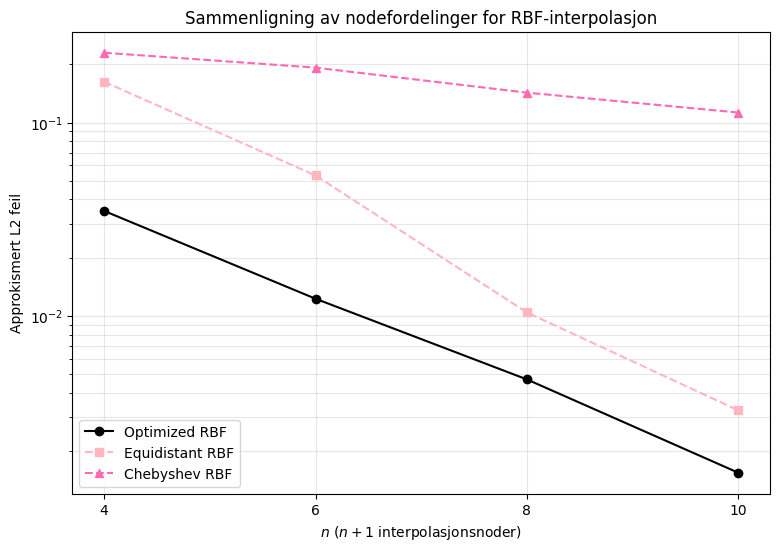

In [362]:
plt.figure(figsize=(9, 6))

plt.semilogy( n_values, errors_opt,"o-", label="Optimized RBF", color="black")

plt.semilogy(n_values, errors_eq, "s--", label="Equidistant RBF", color="lightpink")

plt.semilogy(n_values, errors_cheb,"^--", label="Chebyshev RBF", color="hotpink")

plt.xlabel(r"$n$ ($n+1$ interpolasjonsnoder)")
plt.ylabel("Approkismert L2 feil")
plt.title("Sammenligning av nodefordelinger for RBF-interpolasjon")

plt.xticks(n_values)
plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.show()

#####

### Diskusjon av resultater

Resultatene viser at interpolasjonsfeilen i 2-normen avtar når antall noder øker for alle tre metodene. Den optimaliserte RBF-interpolasjonen gir gjennomgående lavest feil, etterfulgt av ekvidistante noder. Med den samme optimaliserte verdien av $\varepsilon$ gir Chebyshev-nodene betydelig større feil i dette eksperimentet.

For $n=10$ reduseres feilen fra $3.24 \cdot 10^{-3}$ med ekvidistante noder til $1.54 \cdot 10^{-3}$ med optimaliserte noder, en forbedring på omtrent 52 %. Dette viser at nodeplasseringen har betydning for interpolasjonens nøyaktighet.

Chebyshev-nodene er konsentrert mot endepunktene og gir dermed færre noder rundt origo, der Runge-funksjonen varierer mest. Dette kan bidra til den større feilen. Samtidig er $\varepsilon$ optimalisert sammen med de optimaliserte nodene og er ikke nødvendigvis et godt valg for Chebyshev-fordelingen, så forskjellen kan ikke tilskrives nodeplasseringen alene. 

Gradient descent reduserer kostnadsfunksjonen monotont, men stoppkriteriet nås ikke innen 3000 iterasjoner for noen av de undersøkte verdiene av $n$. Resultatene bør derfor tolkes som forbedrede nodefordelinger, ikke som fullt konvergerte optima.

# 1f)

I denne oppgaven erstattes RBF-approksimasjonen fra oppgave 1e med Lagrange-interpolasjonspolynomet

$$
p_n(\eta) = \sum_{i=0}^{n} \ell_i(\eta) f(x_i),
\qquad
\ell_i(\eta) = \prod_{\substack{j=0 \\ j \neq i}}^{n} \frac{\eta - x_j}{x_i - x_j}.
$$

Man ønsker å velge interpolasjonsnodene $x_0, \ldots, x_n$ slik at kostnadsfunksjonen

$$
C(\mathbf{x}) = \frac{b-a}{N} \sum_{k=0}^{N} \bigl(f(\eta_k) - p_n(\eta_k)\bigr)^2
$$

blir minst mulig. Dette er samme diskrete approksimasjon av den kvadrerte 2-normen som i oppgave b),

$$
\|f - p_n\|_2^2 = \int_a^b \bigl(f(x) - p_n(x)\bigr)^2 \, dx,
$$

bare nå med $p_n$, interpolasjon, i stedet for RBF-approksimasjonen $\tilde f$.

### Hvorfor $p_n^*$ er en nedre grense for $C(\mathbf{x})$

Uansett hvilke noder $x_0,\ldots,x_n$ man velger, er interpolasjonspolynomet $p_n$ et polynom av grad $\le n$, altså $p_n \in P_n$. Beste approksimasjonspolynom $p_n^* \in P_n$ er per definisjon det polynomet i $P_n$ som minimerer 2-normen av feilen:

$$
\|f - p_n^*\|_2 = \min_{q \in P_n} \|f - q\|_2.
$$

Siden $p_n \in P_n$ for ethvert nodevalg, følger det direkte at

$$
\|f - p_n\|_2 \;\ge\; \|f - p_n^*\|_2 \qquad \text{for alle valg av } x_0,\ldots,x_n,
$$

med likhet hvis og bare hvis $p_n \equiv p_n^*$. Dette betyr at $\|f-p_n^*\|_2^2$, opp til diskretiseringsfeilen fra det endelige gridet, er den minste verdien $C(\mathbf{x})$ noensinne kan ta. Spørsmålet er derfor: finnes det noder slik at interpolasjonspolynomet faktisk blir lik $p_n^*$, slik at denne nedre grensen nås?

### Eksistens av slike noder

Ifølge **Theorem 9.2** (eksistens og entydighet av beste approksimasjon i indreproduktrom) finnes det nøyaktig ett slikt $p_n^*$. **Theorem 9.3** karakteriserer $p_n^*$ ved at feilen er ortogonal på hele $P_n$:

$$
\langle f - p_n^*, q \rangle = \int_a^b \bigl(f(x) - p_n^*(x)\bigr) q(x) \, dx = 0 \qquad \forall q \in P_n.
$$

Videre sier **Theorem 9.5** at for en kontinuerlig funksjon $f \notin P_n$ skifter feilen

$$
e(x) = f(x) - p_n^*(x)
$$

fortegn i minst $n+1$ forskjellige punkter i $(a,b)$, og har dermed minst $n+1$ nullpunkter der. Denne egenskapen følger av ortogonalitetsbetingelsen: hvis $e$ skiftet fortegn færre enn $n+1$ ganger, kunne man konstruere et $q \in P_n$ med samme fortegnsmønster som $e$, slik at $\int_a^b e(x) q(x)\,dx > 0$ , i strid med ortogonaliteten.

Man velger $n+1$ av disse nullpunktene som interpolasjonsnoder $x_0, \ldots, x_n$. I disse punktene er

$$
f(x_i) - p_n^*(x_i) = 0 \quad\Longrightarrow\quad p_n^*(x_i) = f(x_i), \qquad i = 0, \ldots, n.
$$

Fra **Theorem 6.1** (Lagranges interpolasjonsteorem) vet man at det finnes nøyaktig ett polynom i $P_n$ som interpolerer $f$ i $n+1$ distinkte punkter. Siden $p_n^*$ er et polynom av grad $\le n$ som også interpolerer $f$ i disse punktene, må Lagrange-interpolasjonspolynomet gjennom disse nodene være nettopp $p_n^*$.

$$
\boxed{\text{Med noder valgt som nullpunkter til } f - p_n^*,\ \text{blir } p_n \equiv p_n^*.}
$$

Nedre grensen fra forrige avsnitt nås altså nøyaktig for dette nodevalget, det er derfor disse nodene løser minimeringsproblemet i 1f).

I vårt numeriske problem brukes et endelig grid, så $C(\mathbf{x})$ er bare en approksimasjon av $\|f-p_n\|_2^2$. Det optimaliserte interpolasjonspolynomet vil derfor numerisk tilnærme $p_n^*$ når gridet er tilstrekkelig fint.

### Alternativ måte å beregne $p_n^*$ på

Konsekvensen av dette er at man ikke trenger å finne de optimale nodene med gradient descent (som i 1e) for å få tak i $p_n^*$. Man kan beregne beste approksimasjonspolynom direkte, uten et ikke-lineært optimaliseringsproblem over nodeplassering.

Boka foreslår å bruke en ortogonal basis $\{\phi_0, \phi_1, \ldots, \phi_n\}$ for $P_n$ med hensyn på indreproduktet $\langle u,v\rangle = \int_a^b u(x)v(x)\,dx$ (dvs. vektfunksjon $w(x)=1$). Da kan beste approksimasjonspolynom skrives

$$
p_n^*(x) = \sum_{j=0}^{n} \gamma_j \phi_j(x),
\qquad
\gamma_j = \frac{\langle f, \phi_j \rangle}{\langle \phi_j, \phi_j \rangle}
= \frac{\int_a^b f(x)\phi_j(x)\,dx}{\int_a^b \phi_j(x)^2\,dx}.
$$

På $[-1,1]$ er Legendre-polynomene ortogonale med hensyn på $w(x)=1$ og kan brukes direkte. For et generelt intervall $[a,b]$ må man enten bruke *skiftede* Legendre-polynomer, ortogonale på $[a,b]$, eller transformere via samme avbildning $\Psi:[-1,1]\to[a,b]$ som i oppgave a), $\phi_j(x) = P_j\bigl(\Psi^{-1}(x)\bigr)$, hvor $P_j$ er standard Legendre-polynomer.

Integralene for $\gamma_j$ må i praksis beregnes numerisk, f.eks. med en kvadraturformel, men dette unngår helt det ikke-lineære optimaliseringsproblemet fra 1e. Ønsker man deretter de tilhørende interpolasjonsnodene, kan man finne nullpunktene til $f(x) - p_n^*(x)$ numerisk og velge $n+1$ av disse.

### Konklusjon

Optimalisering av interpolasjonsnodene i 1f) og beregning av beste polynomapproksimasjon i 2-norm er derfor to sider av samme sak: ethvert interpolasjonspolynom ligger i $P_n$, så $\|f-p_n^*\|_2$ er en nedre grense for kostnadsfunksjonen, og denne grensen nås presist når nodene er de $n+1$ nullpunktene til $f - p_n^*$ som garantert finnes (Theorem 9.5). En mer direkte måte å finne $p_n^*$ på er derfor å beregne den ortogonale projeksjonen av $f$ på $P_n$ via en ortogonal polynombasis (f.eks. Legendre-polynomer), i stedet for å optimalisere nodeplasseringen numerisk med gradient descent.